# 1. Preparación de los datos

## 1.1 Instalo e importo las librerías




In [ ]:
# Instalo las versiones utilizadas
%pip install "setuptools<81" numpy==2.3.5 pandas==2.3.3 matplotlib==3.10.0 openpyxl==3.1.5 ipython==9.10.1 numba==0.62.1 fg-data-profiling==4.19.1 geopandas==1.1.4
%pip install scikit-learn==1.6.1 xgboost==2.1.4


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')

# Busco la carpeta donde están los datos.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / 'data/mitula_venta_mar_del_plata_SC.xlsx'


## 1.2 Cargo el Excel y filtro departamentos

Cargo el archivo, me quedo con los departamentos y veo cuántos avisos hay.


In [2]:
propiedades = pd.read_excel(
    DATA_PATH,
    sheet_name='Propiedades',
    engine='openpyxl'
)

cantidad_antes_filtro = len(propiedades)
propiedades = propiedades.loc[propiedades['tipo_propiedad'].eq('Departamento')].copy()
propiedades = propiedades.reset_index(drop=True)

print(f'Avisos antes del filtro: {cantidad_antes_filtro:,}')
print(f'Departamentos: {propiedades.shape[0]:,} filas × {propiedades.shape[1]} columnas')
display(propiedades.head(3))

Avisos antes del filtro: 4,274
Departamentos: 2,731 filas × 81 columnas


,id_aviso,tipo_propiedad,operacion,precio,moneda,precio_publicado,superficie_publicada,superficie_total_m2,superficie_cubierta_m2,superficie_descubierta_m2,superficie_semicubierta_m2,superficie_terreno_m2,ambientes,dormitorios,banos,toilettes,cocheras,antiguedad_anios,anio_construccion,piso,unidad,cantidad_plantas,frente_terreno_m,fondo_terreno_m,expensas,apto_credito,apto_profesional,escritura,estado,disposicion,orientacion,ubicacion,ciudad,partido,provincia,latitud,longitud,tipo_gas,portal_origen,id_aviso_origen,barrio,direccion,circunscripcion,seccion_catastral,manzana,parcela,chacra,titulo,descripcion,fecha_publicacion,actualizacion_relativa,anunciante,publicacion_destacada,amoblamiento,tiene_agua,tiene_aire_acondicionado,tiene_balcon,tiene_calefaccion,tiene_chimenea,tiene_cochera,tiene_electricidad,tiene_gas_natural,tiene_internet,tiene_parrilla,tiene_patio,tiene_piscina,tiene_terraza,tiene_jardin,tiene_ascensor,tiene_seguridad,tiene_wifi,tiene_lavadero,tiene_cocina_equipada,tiene_cocina_integral,tiene_cuarto_servicio,tiene_vista_panoramica,tiene_bodega,tiene_baulera,tiene_cloacas,url_aviso,url_listado
0,019c489b-6ed8-73ae-a54d-bbebeeb2900b,Departamento,venta,"124,800.00",USD,"124,800",41 m²,41.00,41.00,NaN,NaN,NaN,2.00,1.00,1.00,NaN,NaN,NaN,NaN,13.00,NaN,NaN,NaN,NaN,"140,000.00",Sí,NaN,NaN,reciclado,NaN,NaN,"Mar del Plata, General Pueyrredón",Mar del Plata,General Pueyrredón,Provincia de Buenos Aires,-38.01,-57.54,Gas natural / red,NaN,NaN,Plaza Colón,NaN,NaN,NaN,NaN,NaN,NaN,DUEÑO VENDE ! 2 amb reciclado vista al mar,"40 mt, balcón francés, 2 ambientes (1 habitaci...",30 jul 2026,NaN,Ezequiel grevi,Sí,NaN,NaN,NaN,Sí,Sí,NaN,NaN,NaN,Sí,NaN,NaN,NaN,NaN,NaN,NaN,Sí,Sí,NaN,NaN,Sí,Sí,NaN,Sí,NaN,NaN,NaN,https://casas.mitula.com.ar/adform/24301-256-7...,https://casas.mitula.com.ar/casas/st-partido-d...
1,019da4c5-0c4e-76a8-894b-7305efbf99fb,Departamento,venta,"90,900.00",USD,"90,900",41 m²,41.00,37.00,NaN,NaN,NaN,2.00,1.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Reciclado en totalidad (incluyendo cableado el...,NaN,NaN,"Mar del Plata, General Pueyrredón",Mar del Plata,General Pueyrredón,Provincia de Buenos Aires,-38.01,-57.54,NaN,NaN,NaN,Plaza Colón,NaN,NaN,NaN,NaN,NaN,NaN,Venta departamento 2 ambientes a la calle Plaz...,Departamento dos ambientes con balcón corrido ...,NaN,"Hace 4 días, 9 horas en - Indra Persic Propied...",Indra Persic Propiedades,Sí,NaN,Sí,Sí,Sí,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sí,NaN,https://casas.mitula.com.ar/adform/24301-256-7...,https://casas.mitula.com.ar/casas/st-partido-d...
2,019d6c20-b441-7c55-9e21-53352ab7b1a9,Departamento,venta,"64,900.00",USD,"64,900",28 m²,28.00,28.00,NaN,NaN,NaN,1.00,1.00,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,reciclado en su totalidad,Frente,NaN,"Mar del Plata, General Pueyrredón",Mar del Plata,General Pueyrredón,Provincia de Buenos Aires,-38.01,-57.54,NaN,NaN,NaN,Centro,NaN,NaN,NaN,NaN,NaN,NaN,VENTA departamento Plaza Colón Mar del Plata 1...,Departamento 1 ambiente dispuesto al frente co...,30 jul 2026,NaN,Indra Persic Propiedades,Sí,NaN,NaN,NaN,Sí,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,https://casas.mitula.com.ar/adform/24301-256-7...,https://casas.mitula.com.ar/casas/st-partido-d...


## 1.3 Reviso las columnas y los faltantes

Reviso qué tipo de datos tiene cada columna, cuántos están completos, cuántos faltan y cuántos valores distintos hay.


In [4]:
resumen_estructura = pd.DataFrame({
    'tipo_dato': propiedades.dtypes.astype(str),
    'completos': propiedades.notna().sum(),
    'faltantes': propiedades.isna().sum(),
    'cobertura_pct': propiedades.notna().mean().mul(100).round(2),
    'valores_unicos': propiedades.nunique(dropna=True),
})
resumen_estructura = resumen_estructura.sort_values(
    by='cobertura_pct', ascending=False
)
display(resumen_estructura)

,tipo_dato,completos,faltantes,cobertura_pct,valores_unicos
id_aviso,object,2731,0,100.00,2731
tipo_propiedad,object,2731,0,100.00,1
operacion,object,2731,0,100.00,1
url_aviso,object,2731,0,100.00,2731
titulo,object,2731,0,100.00,2154
...,...,...,...,...,...
manzana,object,0,2731,0.00,0
circunscripcion,object,0,2731,0.00,0
id_aviso_origen,float64,0,2731,0.00,0
portal_origen,float64,0,2731,0.00,0


## 1.4 Busco duplicados

Reviso si hay filas, identificadores o enlaces repetidos.


In [5]:
print('Filas duplicadas:', propiedades.duplicated().sum())
print('Identificadores repetidos:', propiedades['id_aviso'].duplicated().sum())
print('Enlaces repetidos:', propiedades['url_aviso'].duplicated().sum())


Filas duplicadas: 0
Identificadores repetidos: 0
Enlaces repetidos: 0


## 1.5 Reviso las categorías

Veo cuáles son las categorías más frecuentes en cada columna.


In [6]:
categoricas = propiedades.select_dtypes(exclude='number').columns.tolist()

for columna in categoricas:
    cantidad_categorias = propiedades[columna].nunique(dropna=True)
    print(f'\nDistribución de {columna} ({cantidad_categorias:,} valores únicos)')
    print('Se muestran los 3 valores más frecuentes.')
    display(
        propiedades[columna].value_counts(dropna=False)
        .head(3).rename_axis(columna).to_frame('cantidad')
    )


Distribución de id_aviso (2,731 valores únicos)
Se muestran los 3 valores más frecuentes.


,cantidad
id_aviso,
019c489b-6ed8-73ae-a54d-bbebeeb2900b,1
019da4c5-0c4e-76a8-894b-7305efbf99fb,1
019d6c20-b441-7c55-9e21-53352ab7b1a9,1



Distribución de tipo_propiedad (1 valores únicos)
Se muestran los 3 valores más frecuentes.


,cantidad
tipo_propiedad,
Departamento,2731



Distribución de operacion (1 valores únicos)
Se muestran los 3 valores más frecuentes.


...

,cantidad
tiene_cloacas,
NaN,2695
Sí,36



Distribución de url_aviso (2,731 valores únicos)
Se muestran los 3 valores más frecuentes.


,cantidad
url_aviso,
https://casas.mitula.com.ar/adform/24301-256-74ae-bbebeeb2910b-a64d-19c499b-6fd8?page=1&pos=1&t_sec=1&t_pvid=10bee824-8b3d-4199-af0c-ea180adf6c08&hd=false,1
https://casas.mitula.com.ar/adform/24301-256-77a8-7305efbf9afb-8a4b-19da5c5-d4e?page=1&pos=2&t_sec=1&t_pvid=10bee824-8b3d-4199-af0c-ea180adf6c08&hd=false,1
https://casas.mitula.com.ar/adform/24301-256-7d55-53352ab7b2a9-9f21-19d6d20-b541?page=1&pos=3&t_sec=1&t_pvid=10bee824-8b3d-4199-af0c-ea180adf6c08&hd=false,1



Distribución de url_listado (196 valores únicos)
Se muestran los 3 valores más frecuentes.


,cantidad
url_listado,
https://casas.mitula.com.ar/casas/st-partido-de-general-pueyrredon-buenos-aires?page=97,57
https://casas.mitula.com.ar/casas/st-partido-de-general-pueyrredon-buenos-aires?page=95,54
https://casas.mitula.com.ar/casas/st-partido-de-general-pueyrredon-buenos-aires?page=96,50


## 1.6 Resumo las variables numéricas

Reviso los mínimos, máximos, promedios, medianas y percentiles de las columnas numéricas.


In [7]:
numericas = propiedades.select_dtypes(include='number').columns.tolist()
print(f'Cantidad de columnas numéricas: {len(numericas)}')

resumen_numericas = (
    propiedades[numericas]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)
resumen_numericas.index.name = 'columna'
display(resumen_numericas)


Cantidad de columnas numéricas: 23


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
columna,,,,,,,,,,,,
precio,"2,719.00","116,842.16","105,262.54",1.00,"39,000.00","48,000.00","67,900.00","94,000.00","134,900.00","250,000.00","450,000.00","2,690,000.00"
superficie_total_m2,"2,313.00",64.52,131.06,1.00,21.00,26.00,39.00,51.00,70.00,126.40,222.64,"5,360.00"
superficie_cubierta_m2,"1,256.00",60.75,75.83,1.00,19.55,25.00,38.00,50.00,68.62,112.00,187.80,"2,007.00"
superficie_descubierta_m2,7.00,6.60,3.33,4.30,4.34,4.49,4.94,6.00,6.00,11.60,13.52,14.00
superficie_semicubierta_m2,1.00,14.00,NaN,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00,14.00
superficie_terreno_m2,"1,491.00","3,021.71","59,499.57",8.00,21.00,25.00,39.00,51.00,70.50,140.00,377.50,"1,750,000.00"
ambientes,"2,230.00",32.49,"1,333.44",1.00,1.00,1.00,2.00,2.00,3.00,4.00,4.00,"62,900.00"
dormitorios,"2,296.00",1.62,0.77,1.00,1.00,1.00,1.00,1.00,2.00,3.00,4.00,12.00
banos,"2,705.00",1.40,1.78,1.00,1.00,1.00,1.00,1.00,2.00,2.00,3.00,55.00


## 1.7 Observo las distribuciones

Uso histogramas y boxplots para ver cómo se distribuyen los valores y cuáles se alejan del resto.


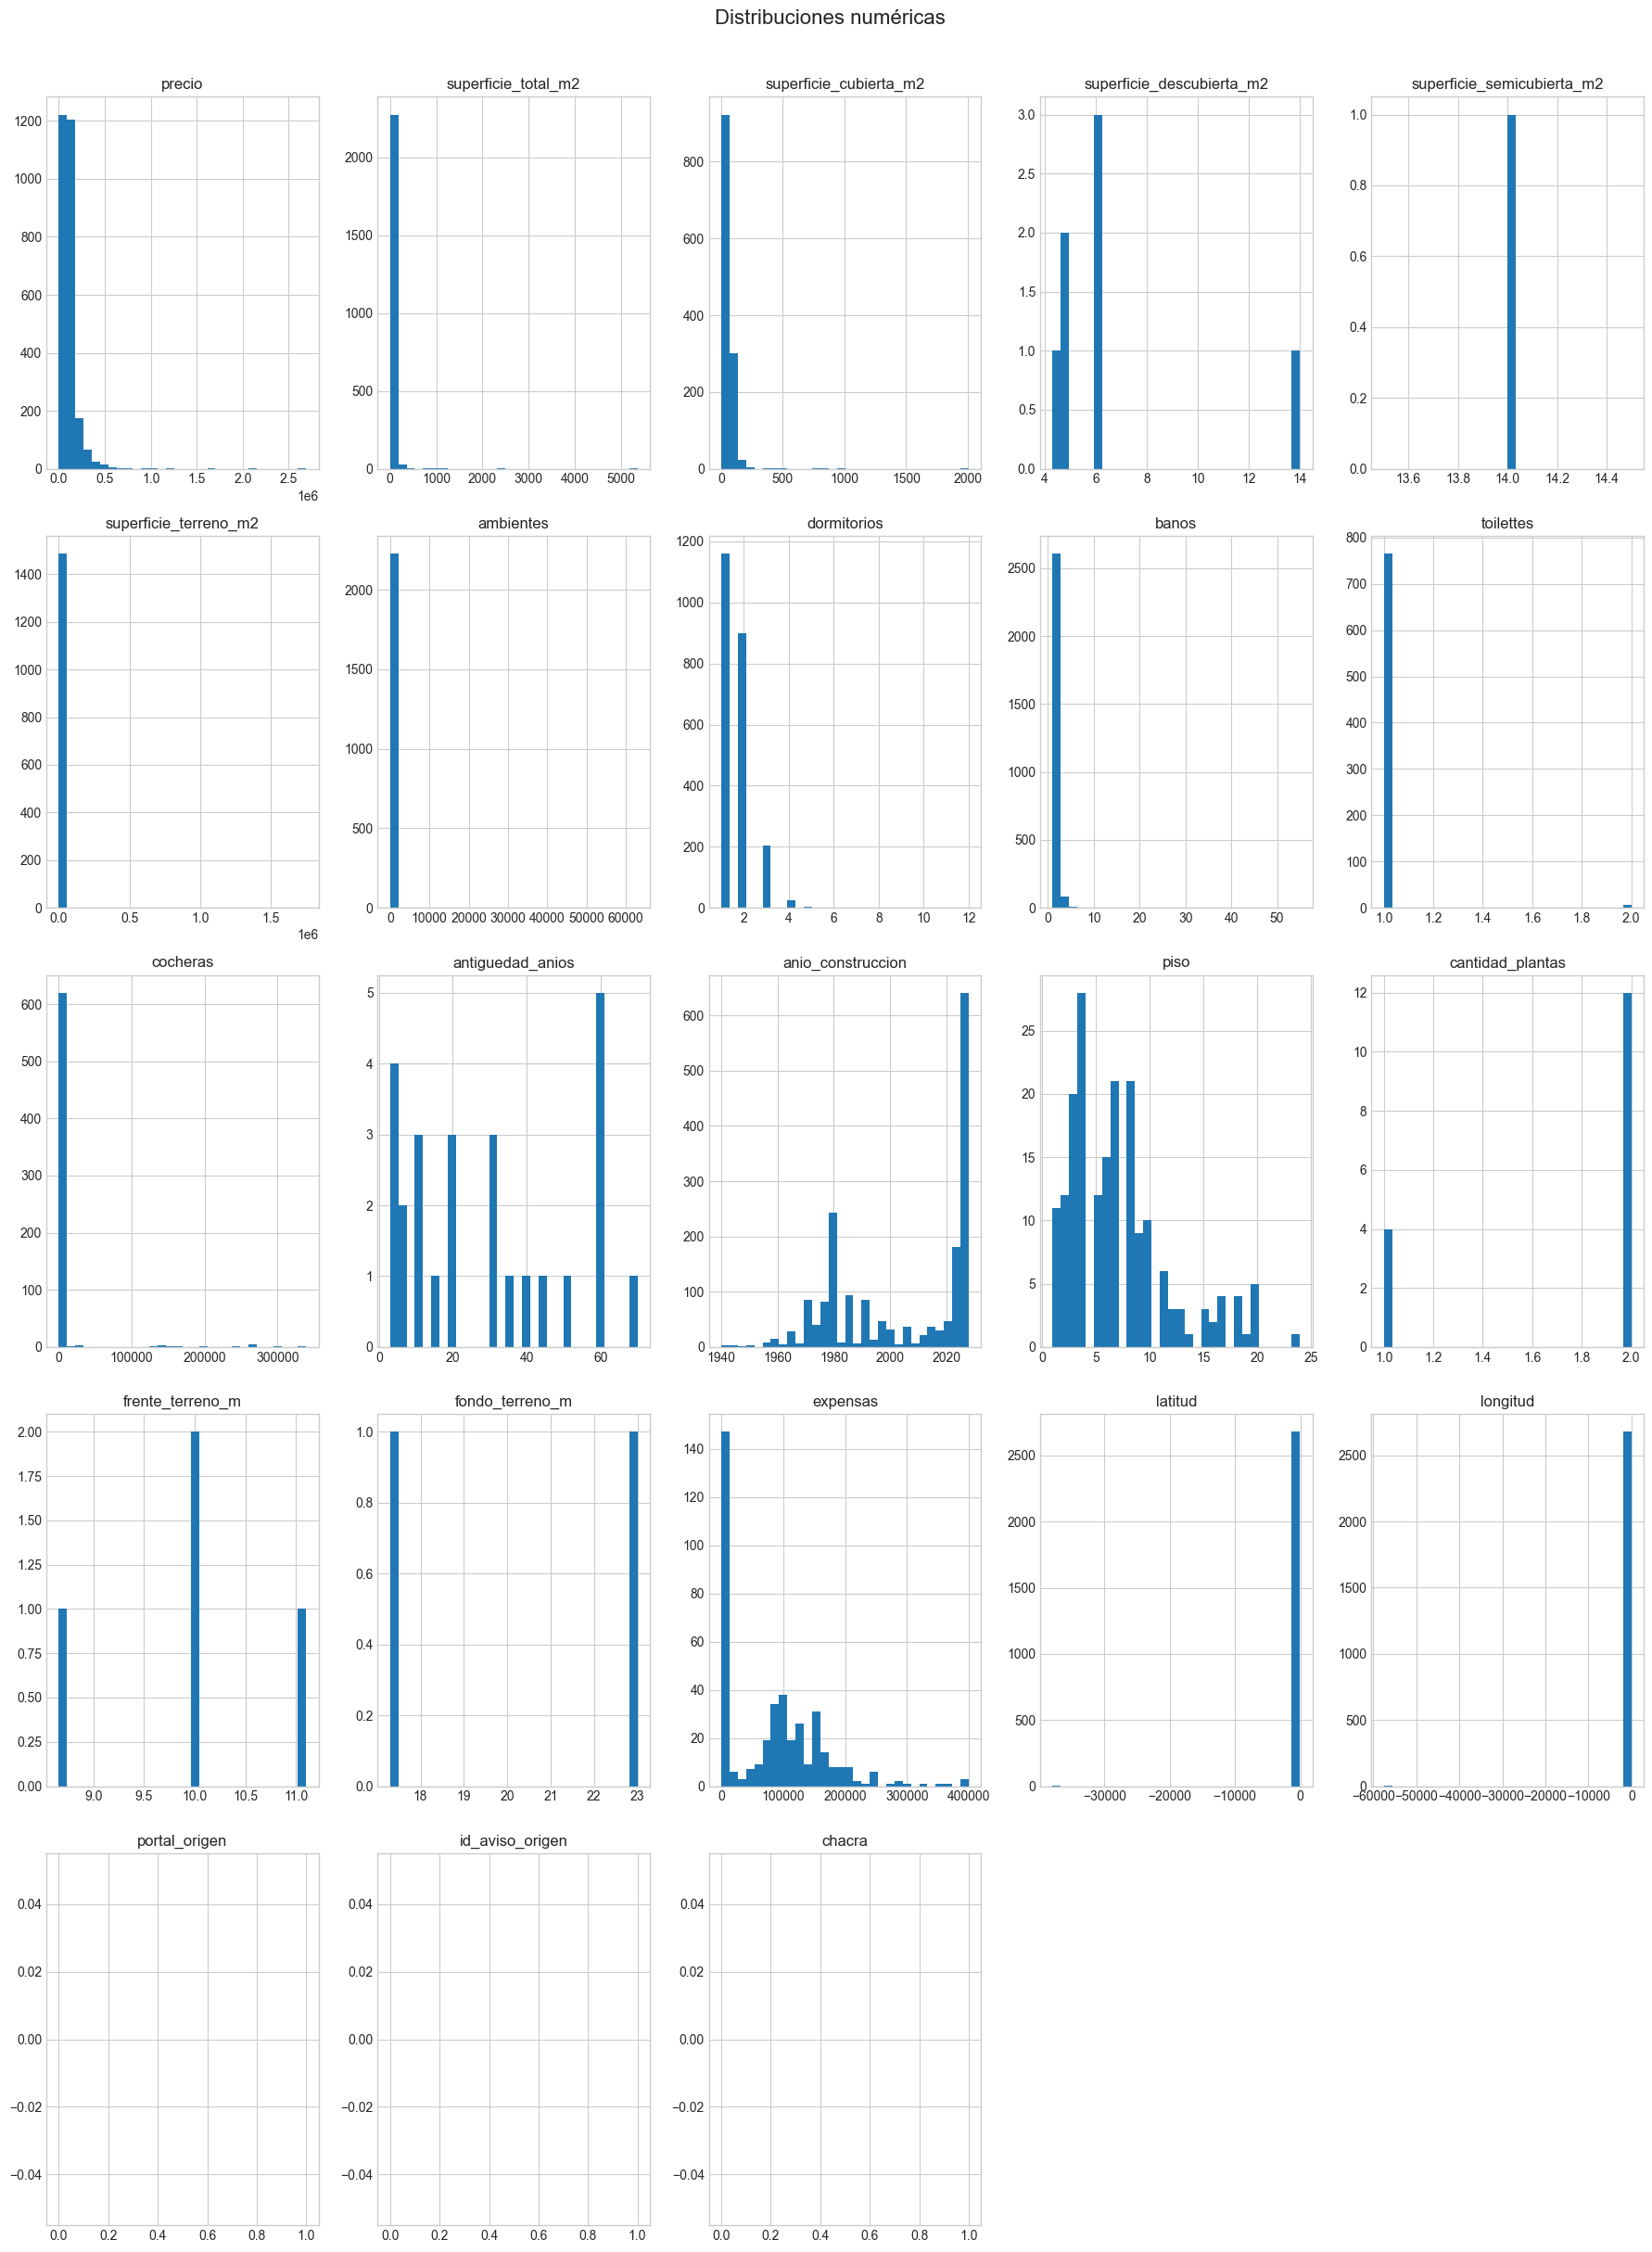

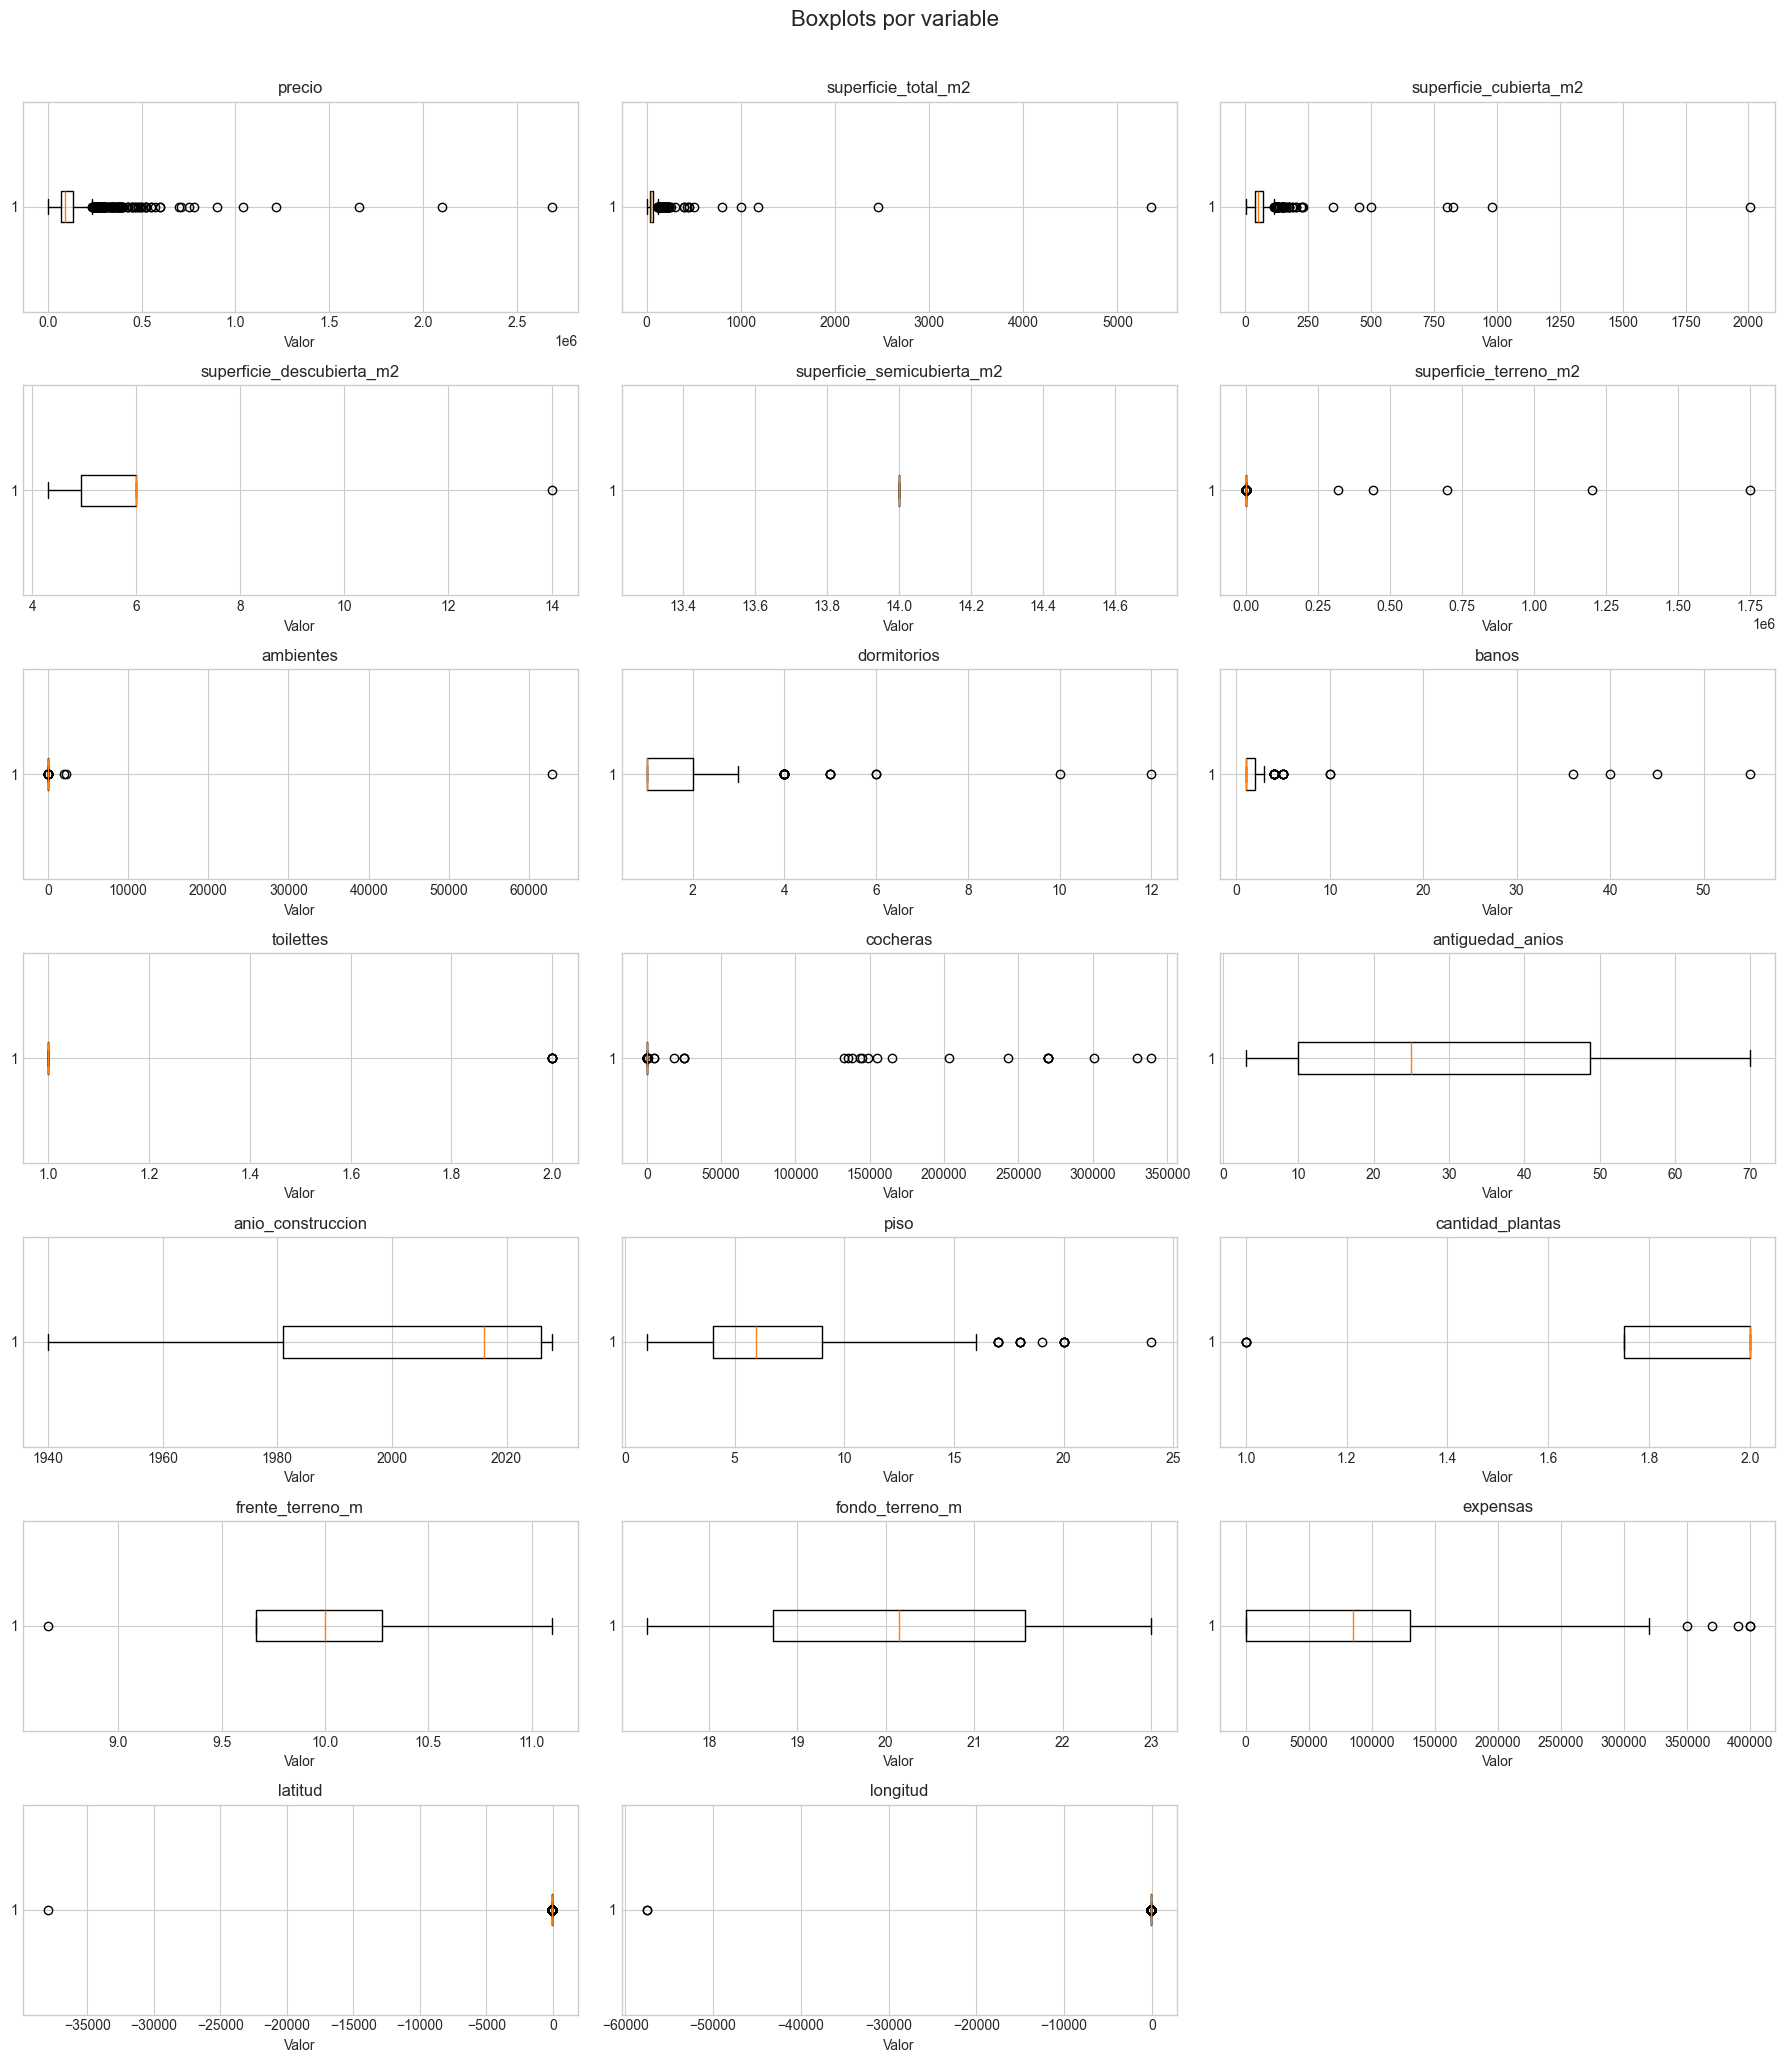

In [8]:
propiedades[numericas].hist(figsize=(18, 24), bins=30)
plt.suptitle('Distribuciones numéricas', y=1.01, fontsize=16)
plt.tight_layout()
plt.show()

columnas_con_datos = [
    columna for columna in numericas
    if propiedades[columna].notna().any()
]
if columnas_con_datos:
    filas = (len(columnas_con_datos) + 2) // 3
    fig, axes = plt.subplots(filas, 3, figsize=(18, 3 * filas), squeeze=False)
    for ax, columna in zip(axes.flat, columnas_con_datos):
        ax.boxplot(propiedades[columna].dropna(), vert=False)
        ax.set_title(columna)
        ax.set_xlabel('Valor')
    for ax in list(axes.flat)[len(columnas_con_datos):]:
        ax.set_visible(False)
    fig.suptitle('Boxplots por variable', fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


## 1.8 Reporte automático

Genero un reporte para complementar la revisión de los datos.


In [9]:
from data_profiling import ProfileReport
from IPython.display import FileLink

# Genero el reporte con los datos del EDA.
reporte = ProfileReport(
    propiedades,
    title='EDA de departamentos en venta - Mar del Plata',
    interactions={'continuous': False},
    vars={
        'text': {'words': False, 'characters': False},
        'cat': {'words': False, 'characters': False},
    },
    pool_size=1,
    progress_bar=False,
)

# Guardo el reporte en un archivo HTML.
Path('reportes').mkdir(exist_ok=True)
reporte.to_file('reportes/eda_departamentos.html')
display(FileLink('reportes/eda_departamentos.html'))


c:\Users\Joaquin\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 81/81 [00:03<00:00, 21.99it/s]
c:\Users\Joaquin\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


c:\Users\Joaquin\OneDrive\Escritorio\SCRAPING TFI\DATA_MODELING\reportes\eda_departamentos.html

## 1.9 Creo una copia

Hago la limpieza sobre una copia de los departamentos que seleccioné en el EDA.


In [3]:
# Copio los departamentos cargados en el EDA.
departamentos_limpios = propiedades.copy()


## 1.10 Limpio los textos

Quito espacios de más y dejo las respuestas Sí y No escritas de la misma manera.


In [4]:
# Quito espacios de más y marco los textos vacíos como faltantes.
columnas_texto = departamentos_limpios.select_dtypes(include=['object', 'string']).columns
for columna in columnas_texto:
    departamentos_limpios[columna] = (
        departamentos_limpios[columna].astype('string')
        .str.replace('\u00a0', ' ', regex=False).str.strip().replace('', pd.NA)
    )

# Unifico el nombre de la provincia.
departamentos_limpios['provincia'] = departamentos_limpios['provincia'].replace(
    {'Buenos Aires': 'Provincia de Buenos Aires'}
)

# Dejo las respuestas escritas como Sí o No.
columnas_binarias = [c for c in departamentos_limpios if c.startswith('tiene_')]
columnas_binarias += ['apto_credito', 'apto_profesional', 'escritura', 'publicacion_destacada']
respuestas = {'si': 'Sí', 'sí': 'Sí', 'true': 'Sí', '1': 'Sí',
              'no': 'No', 'false': 'No', '0': 'No'}
for columna in columnas_binarias:
    departamentos_limpios[columna] = (
        departamentos_limpios[columna].str.lower().map(respuestas).astype('string')
    )


## 1.11 Completo datos desde la descripción

Busco en la descripción las cantidades, superficies y características que faltan. Uso distintas formas de escribir el mismo dato y completo los casos en los que encuentro una respuesta clara.


In [5]:
import re

# Paso el texto a minúsculas y quito tildes y espacios de más para buscar.
descripcion = (
    departamentos_limpios['descripcion'].fillna('').str.lower()
    .str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')
    .str.replace(r'\s+', ' ', regex=True)
)

# Busco cantidades escritas con números o con palabras.
numeros_escritos = {
    'cero': 0, 'un': 1, 'una': 1, 'uno': 1, 'dos': 2, 'tres': 3,
    'cuatro': 4, 'cinco': 5, 'seis': 6, 'siete': 7, 'ocho': 8,
    'nueve': 9, 'diez': 10, 'once': 11, 'doce': 12, 'trece': 13,
    'catorce': 14, 'quince': 15, 'dieciseis': 16, 'diecisiete': 17,
    'dieciocho': 18, 'diecinueve': 19, 'veinte': 20,
}
cantidad = r'(?<![\w.,/])(?:\d+|' + '|'.join(numeros_escritos) + r')(?!\d|[.,/]\d)'
numero_superficie = r'(?<![\w.,/])\d+(?:[.,]\d+)*(?!\d|[.,/]\d)'
unidad = r'(?:m\s*(?:\^\s*)?2|mts?\.?\s*2|mtrs?\.?\s*2|metros?\s*(?:cuadrados?|2))\b'

# Ajusto los puntos y las comas para leer los números.
def convertir_numero(texto):
    if re.fullmatch(r'mono[ -]?ambientes?', texto):
        return 1
    if texto.startswith(('sin ', 'no ')):
        return 0
    if texto in numeros_escritos:
        return numeros_escritos[texto]
    if ',' in texto and '.' in texto:
        if texto.rfind(',') > texto.rfind('.'):
            texto = texto.replace('.', '').replace(',', '.')
        else:
            texto = texto.replace(',', '')
    elif re.fullmatch(r'\d{1,3}(?:[.,]\d{3})+', texto):
        texto = texto.replace('.', '').replace(',', '')
    else:
        texto = texto.replace(',', '.')
    return pd.to_numeric(texto, errors='coerce')

# Si aparecen cantidades diferentes para el mismo dato, lo dejo sin completar.
def extraer_valor(texto, expresiones):
    valores = {
        convertir_numero(coincidencia)
        for patron in expresiones
        for coincidencia in re.findall(patron, texto)
    }
    valores = {valor for valor in valores if pd.notna(valor)}
    return valores.pop() if len(valores) == 1 else np.nan

# Busco la cantidad antes o después del nombre, también con abreviaturas.
nombres_cantidades = {
    'ambientes': r'ambientes?|ambs?\.?',
    'dormitorios': r'dormitorios?|dorms?\.?|habitacion(?:es)?|hab(?:s|it)?\.?|recamaras?',
    'banos': r'banos?',
    'toilettes': r'toilettes?|toilets?|toilet(?:es)?|toiletes?|toilett',
    'cocheras': r'cocheras?|coch\.?|garajes?|garages?|plazas? de (?:garaje|garage|estacionamiento)',
}
for columna, nombre in nombres_cantidades.items():
    expresiones = [
        r'(' + cantidad + r')\s*(?:' + nombre + r')(?!\w)',
        r'\b(?:' + nombre + r')\s*[:=]\s*(' + cantidad + r')',
        r'\bcantidad de (?:' + nombre + r')\s*(?:[:=]|de)?\s*(' + cantidad + r')',
    ]
    if columna == 'ambientes':
        expresiones.append(r'\b(mono[ -]?ambientes?)\b')
    if columna == 'cocheras':
        expresiones.append(r'\b(sin cocheras?|sin garajes?|sin garages?|no (?:tiene|posee|cuenta con) cocheras?)\b')
    encontrado = descripcion.apply(lambda texto: extraer_valor(texto, expresiones))
    departamentos_limpios[columna] = departamentos_limpios[columna].fillna(encontrado)

# Distingo la superficie total, cubierta, descubierta y semicubierta.
tipos_superficie = {
    'superficie_total_m2': r'total(?:es)?|tot\.?',
    'superficie_cubierta_m2': r'cubiert[oa]s?|cub\.?|cubta\.?',
    'superficie_descubierta_m2': r'descubiert[oa]s?|descub\.?|desc\.?',
    'superficie_semicubierta_m2': r'semi[ -]?cubiert[oa]s?|semi[ -]?cub\.?',
}
prefijo = r'(?:superficies?|sup\.?|supf\.?|metros?)(?:\s*[:=])?\s*'
enlace = r'\s*(?:(?:aprox(?:imadamente)?\.?|de|es de|son)\s*)?[:=]?\s*'

# Dejo aparte medidas como 4 x 5 para no tomar el 5 como una superficie.
texto_superficies = descripcion.str.replace(
    r'\b\d+(?:[.,]\d+)?\s*[x*]\s*\d+(?:[.,]\d+)?\b', 'medidas', regex=True
)
for columna, tipo in tipos_superficie.items():
    # Busco cada tipo de superficie por separado.
    etiqueta = r'(?<!semi )(?<!semi-)(?<!\w)(?:' + tipo + r')(?!\w)'
    expresiones = [
        r'(' + numero_superficie + r')\s*' + unidad + r'\s*(?:de\s+)?(?:' + prefijo + r')?' + etiqueta,
        r'(' + numero_superficie + r')\s*(?:' + prefijo + r')?' + etiqueta + r'\s*' + unidad,
        r'\b' + prefijo + etiqueta + enlace + r'(' + numero_superficie + r')',
        etiqueta + enlace + r'(' + numero_superficie + r')\s*' + unidad,
    ]
    encontrado = texto_superficies.apply(lambda texto: extraer_valor(texto, expresiones))
    departamentos_limpios[columna] = departamentos_limpios[columna].fillna(encontrado)


In [6]:
# Busco las distintas formas de mencionar cada comodidad.
comodidades = {
    'tiene_balcon': r'balcon(?:es)?',
    'tiene_cochera': r'cocheras?|garajes?|garages?|plazas? de estacionamiento|espacios? guardacoches',
    'tiene_calefaccion': r'calefaccion|calefactor(?:es)?|losa radiante|piso radiante|radiador(?:es)?|estufas? de tiro balanceado',
    'tiene_aire_acondicionado': r'aires? acondicionados?|equipos? split|split frio[ /-]*calor',
    'tiene_ascensor': r'ascensor(?:es)?|elevador(?:es)?',
    'tiene_gas_natural': r'gas natural|gas de red|gas por red|servicio de gas conectado',
    'tiene_agua': r'agua corriente|agua de red|agua potable|red de agua',
    'tiene_electricidad': r'electricidad|energia electrica|luz electrica|red electrica|instalacion electrica',
    'tiene_internet': r'internet|fibra optica|banda ancha',
    'tiene_wifi': r'wi[ -]?fi|conexion inalambrica a internet',
    'tiene_lavadero': r'lavaderos?|laundry|sala de lavado',
    'tiene_parrilla': r'parrillas?|parrilleros?|barbacoa',
    'tiene_patio': r'patios?',
    'tiene_terraza': r'terrazas?|azotea transitable',
    'tiene_jardin': r'jardin(?:es)?',
    'tiene_piscina': r'piscinas?|natatorio|swimming pool|piletas?(?!\s+(?:de\s+)?(?:cocina|lavar|lavado|lavadero|bano))',
    'tiene_baulera': r'bauleras?|trasteros?',
    'tiene_seguridad': r'seguridad|vigilancia|camaras de seguridad|control de acceso|porteria\s*(?:las\s*)?24\s*(?:hs?|horas)?',
    'tiene_cloacas': r'cloacas?|red cloacal|desague cloacal|servicio cloacal',
    'tiene_chimenea': r'chimeneas?|hogar a lena|estufa hogar',
    'tiene_cocina_equipada': r'cocina (?:completamente |totalmente )?equipada',
}

# Tengo en cuenta frases como "sin balcón ni patio".
lista_comodidades = r'(?:' + '|'.join(comodidades.values()) + r')'
negacion = r'\b(?:sin|no tiene|no posee|no hay|no dispone de|no cuenta con|carece de)\s+'
lista_negada = r'(?:' + lista_comodidades + r'\s*(?:,\s*(?:ni\s+)?|ni\s+|y\s+))*'

# Dejo sin completar las comodidades opcionales o que todavía no están instaladas.
pendiente = r'\b(?:opcional(?:es)?|opcion|posibilidad|preinstalacion|preparad[oa]|proyectad[oa]|a instalar|a construir)\b'

def extraer_comodidad(texto, patron):
    elemento = r'\b(?:' + patron + r')\b'
    negativas = negacion + lista_negada + elemento + r'|' + elemento + r'\s*:\s*no\b'
    opcionales = (
        pendiente + r'[^.;]{0,45}' + elemento
        + r'|' + elemento + r'[^.;]{0,30}' + pendiente
    )
    # Si es opcional, dejo el dato sin completar.
    if re.search(opcionales, texto):
        return pd.NA
    niega = bool(re.search(negativas, texto))
    texto_afirmativo = re.sub(negativas, '', texto)
    afirma = bool(re.search(elemento, texto_afirmativo))
    if niega and not afirma:
        return 'No'
    if afirma and not niega:
        return 'Sí'
    return pd.NA

# Completo los faltantes. Si la descripción no lo menciona, no pongo No.
for columna, patron in comodidades.items():
    falta = departamentos_limpios[columna].isna()
    encontrado = descripcion.loc[falta].apply(lambda texto: extraer_comodidad(texto, patron))
    departamentos_limpios.loc[falta, columna] = encontrado

# Busco si el departamento es al frente, contrafrente, lateral o interno.
disposiciones = {
    'Frente': r'\b(?:al frente|a la calle|disposicion\s*:?\s*frente)\b',
    'Contrafrente': r'\b(?:contrafrente|contra frente)\b',
    'Lateral': r'\b(?:al lateral|disposicion\s*:?\s*lateral|departamento lateral)\b',
    'Interno': r'\b(?:departamento interno|unidad interna|disposicion\s*:?\s*intern[oa])\b',
}

# Busco norte, sur, este y oeste cuando el texto habla de orientación.
puntos_cardinales = {
    'Norte': 'norte', 'Sur': 'sur', 'Este': 'este', 'Oeste': 'oeste',
    'Noreste': r'noreste|nordeste|nor[- ]este',
    'Noroeste': r'noroeste|nor[- ]oeste',
    'Sudeste': r'sudeste|sureste|sur[- ]este',
    'Sudoeste': r'sudoeste|suroeste|sur[- ]oeste',
}
orientaciones = {
    nombre: r'\b(?:orientacion|orientad[oa]s?)\s*:?\s*(?:(?:hacia|al|a|el|la)\s+)*(?:'
    + patron + r')\b(?![- ](?:este|oeste)\b)'
    for nombre, patron in puntos_cardinales.items()
}

# Identifico frases sobre muebles.
sin_muebles = r'\b(?:sin\s+(?:muebles|amoblar|amueblar)|no\s+(?:esta\s+|se\s+(?:vende|entrega)\s+)?(?:amoblad[oa]|amueblad[oa]))\b'
texto_muebles = descripcion.str.replace(sin_muebles, '', regex=True)
amueblado = texto_muebles.str.contains(
    r'\b(?:amoblad[oa]|amueblad[oa]|se\s+(?:vende|entrega)\s+con\s+muebles)\b'
)
sin_amueblar = descripcion.str.contains(sin_muebles)

muebles_opcionales = descripcion.str.contains(
    r'\b(?:opcional\w*|opcion|posibilidad)\b[^.\n]{0,60}\b(?:muebles|amoblar|amueblar|amoblad[oa]|amueblad[oa])\b'
    r'|\b(?:muebles|amoblad[oa]|amueblad[oa])\b[^.\n]{0,40}\bopcional\w*\b'
    r'|\bcon\s+o\s+sin\s+muebles\b'
)

# Completo el dato vacío solo si encuentro una respuesta clara.
coincidencias = {
    'disposicion': pd.DataFrame({nombre: descripcion.str.contains(patron)
                                for nombre, patron in disposiciones.items()}),
    'orientacion': pd.DataFrame({nombre: descripcion.str.contains(patron)
                                for nombre, patron in orientaciones.items()}),
    'amoblamiento': pd.DataFrame({
        'Amueblado': amueblado & ~muebles_opcionales,
        'Sin amueblar': sin_amueblar & ~muebles_opcionales,
    }),
}
for columna, opciones in coincidencias.items():
    completar = departamentos_limpios[columna].isna() & opciones.sum(axis=1).eq(1)
    departamentos_limpios.loc[completar, columna] = opciones.loc[completar].idxmax(axis=1)


## 1.12 Unifico categorías

Agrupo las distintas formas de escribir el estado, la disposición y la orientación. Si el estado combina varias etiquetas, primero considero si está en construcción, necesita reformas, fue reciclado o sigue original, ademas cuando no puedo identificar una categoría, dejo el dato sin completar.


In [7]:
# Dejo los nombres con la misma escritura y quito espacios de más.
for columna in ['amoblamiento', 'tipo_gas', 'barrio']:
    departamentos_limpios[columna] = departamentos_limpios[columna].str.strip().str.capitalize()

# Paso los textos a minúsculas y quito las tildes para comparar.
textos_categorias = departamentos_limpios[['estado', 'disposicion', 'orientacion']].copy()
for columna in textos_categorias:
    textos_categorias[columna] = (
        textos_categorias[columna].fillna('').str.lower().str.normalize('NFKD')
        .str.encode('ascii', errors='ignore').str.decode('utf-8')
        .str.replace(r'\s+', ' ', regex=True).str.strip()
    )

# Uso este orden si hay varias etiquetas, como "reciclado a estrenar".
estados = {
    'En construcción': r'\b(?:en construccion|en obra|en pozo|a terminar)\b',
    'A reciclar': r'\b(?:a reciclar|para reciclar|a refaccionar|para refaccionar|a remodelar|para remodelar|ideal para modernizar)\b',
    'Reciclado': r'\b(?:reciclad[oa]|refaccionad[oa]|remodelad[oa]|renovad[oa])\b',
    'Original': r'\boriginal\b',
    'A estrenar': r'\ba estrenar\b',
    'Excelente': r'\b(?:excelente|impecable)\b',
    'Muy bueno': r'\b(?:muy buen(?:o| estado)|muy bien conservad[oa]|muy buenas condiciones)\b',
    'Bueno': r'\b(?:bueno|buen estado|bien conservad[oa])\b',
    'Regular': r'\bregular\b',
    'Malo': r'\b(?:malo|mal estado|deteriorad[oa])\b',
    'Normal': r'\bnormal\b',
}

def normalizar_estado(texto):
    for categoria, patron in estados.items():
        if re.search(patron, texto):
            return categoria
    return pd.NA

# Agrupo las disposiciones y conservo las combinaciones, como frente y contrafrente.
disposiciones = {
    'Frente': r'\bfrente\b|\ba la calle\b',
    'Contrafrente': r'\bcontrafrente\b',
    'Lateral': r'\blateral\b',
    'Interno': r'\bintern[oa]\b',
}

def normalizar_disposicion(texto):
    texto = re.sub(r'\bcontra[ -]+frente\b', 'contrafrente', texto)
    categorias = [nombre for nombre, patron in disposiciones.items() if re.search(patron, texto)]
    return ' y '.join(categorias) if categorias else pd.NA

# Aprovecho la disposición escrita en orientación si falta en su columna.
disposicion = textos_categorias['disposicion'].apply(normalizar_disposicion)
desde_orientacion = textos_categorias['orientacion'].apply(normalizar_disposicion)
departamentos_limpios['disposicion'] = disposicion.fillna(desde_orientacion)

# Escribo las orientaciones con el nombre completo.
abreviaturas = {
    'n': 'Norte', 's': 'Sur', 'e': 'Este', 'o': 'Oeste', 'w': 'Oeste',
    'ne': 'Noreste', 'no': 'Noroeste', 'nw': 'Noroeste',
    'se': 'Sudeste', 'so': 'Sudoeste', 'sw': 'Sudoeste',
}
cardinales = {
    'Norte': r'norte', 'Sur': r'sur', 'Este': r'este', 'Oeste': r'oeste',
    'Noreste': r'noreste|nordeste', 'Noroeste': r'noroeste',
    'Sudeste': r'sudeste|sureste', 'Sudoeste': r'sudoeste|suroeste',
}

def normalizar_orientacion(texto):
    texto = re.sub(r'\b(?:orientacion|orientad[oa])\s*:?\s*', '', texto).strip()
    abreviada = texto.replace('.', '').replace(' ', '')
    if abreviada in abreviaturas:
        return abreviaturas[abreviada]
    texto = re.sub(r'\b(nor|sur)[ -]+(este|oeste)\b', r'\1\2', texto)
    categorias = [nombre for nombre, patron in cardinales.items()
                  if re.search(r'\b(?:' + patron + r')\b', texto)]
    return ' y '.join(categorias) if categorias else pd.NA

departamentos_limpios['estado'] = textos_categorias['estado'].apply(normalizar_estado)
departamentos_limpios['orientacion'] = textos_categorias['orientacion'].apply(normalizar_orientacion)


## 1.13 Selecciono los registros

Me quedo con los avisos que tienen un precio mayor que cero en dólares y quito las publicaciones repetidas.

Excluyo el aviso de El Malecón que ofrece varias unidades sin una superficie asociada al precio. Registro la revisión en `data/correcciones_avisos.json`.


In [8]:
# Me quedo con los precios mayores que cero en dólares.
departamentos_limpios = departamentos_limpios.loc[
    departamentos_limpios['moneda'].eq('USD')
    & departamentos_limpios['precio'].gt(0)
].copy()

# Dejo los textos con el mismo formato para comparar los avisos.
for columna in ['titulo', 'descripcion']:
    departamentos_limpios[columna + '_comparacion'] = (
        departamentos_limpios[columna].str.lower().str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )

# Quito los avisos repetidos que coinciden en texto, precio, superficie y ubicación.
claves = ['titulo_comparacion', 'descripcion_comparacion', 'precio',
          'superficie_total_m2', 'latitud', 'longitud']
datos_completos = departamentos_limpios.dropna(subset=claves)
repetidos = datos_completos.index[datos_completos.duplicated(subset=claves)]
departamentos_limpios = departamentos_limpios.drop(index=repetidos)
departamentos_limpios = departamentos_limpios.drop(
    columns=['titulo_comparacion', 'descripcion_comparacion']
).reset_index(drop=True)


# Aplico las exclusiones de avisos revisados manualmente.
import json
correcciones_avisos = json.loads(
    (PROJECT_ROOT / 'data/correcciones_avisos.json').read_text(encoding='utf-8')
)
ids_excluidos = [c['id_aviso'] for c in correcciones_avisos if c['accion'] == 'excluir']
departamentos_limpios = departamentos_limpios.loc[
    ~departamentos_limpios['id_aviso'].isin(ids_excluidos)
].reset_index(drop=True)


## 1.14 Obtengo el barrio y las distancias al mar y al centro

Uso las coordenadas para ubicar cada departamento y calcular su distancia al mar y al centro en línea recta. Para el centro tomo como referencia Plaza San Martín, con latitud -37.9983155 y longitud -57.5480057.

[Fuente de las coordenadas de Plaza San Martín](https://ar.near-place.com/plaza-san-martin-microcentro-mar-del-plata).

Corrijo Catamarca 2147 (zona Plaza Mitre, agrupada en Centro) y Rivas al 2400 (Varese). Para Rivas uso una ubicación aproximada a la cuadra, por lo que sus distancias también son aproximadas. Las fuentes y coordenadas quedan en `data/correcciones_avisos.json`.


In [9]:
import geopandas as gpd

# Divido por mil las coordenadas que quedaron guardadas en esa escala.
latitud = departamentos_limpios['latitud'].between(-39000, -37000)
longitud = departamentos_limpios['longitud'].between(-59000, -56000)
departamentos_limpios.loc[latitud, 'latitud'] /= 1000
departamentos_limpios.loc[longitud, 'longitud'] /= 1000

# Corrijo las coordenadas de los avisos verificados antes de medir distancias.
ubicaciones_corregidas = [c for c in correcciones_avisos if c['accion'] == 'corregir_ubicacion']
for correccion in ubicaciones_corregidas:
    aviso = departamentos_limpios['id_aviso'].eq(correccion['id_aviso'])
    departamentos_limpios.loc[aviso, ['latitud', 'longitud']] = [
        correccion['latitud'], correccion['longitud']
    ]

# Armo un punto con la latitud y la longitud de cada aviso.
ubicaciones = departamentos_limpios.dropna(subset=['latitud', 'longitud'])
puntos = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(ubicaciones['longitud'], ubicaciones['latitud']),
    index=ubicaciones.index, crs='EPSG:4326'
)

# Busco en qué barrio cae cada punto.
barrios = gpd.read_file(PROJECT_ROOT / 'data/barrios_mar_del_plata.geojson').to_crs(puntos.crs)
cruce = gpd.sjoin(puntos, barrios[['soc_fomen', 'geometry']], how='left', predicate='within')
barrios_encontrados = cruce.groupby(level=0)['soc_fomen'].first().str.title()
departamentos_limpios['barrio'] = barrios_encontrados.reindex(
    departamentos_limpios.index
).fillna(departamentos_limpios['barrio'])

# Unifico los nombres después de combinar el mapa con las publicaciones.
nombres_barrios = (
    departamentos_limpios['barrio'].astype('string')
    .str.normalize('NFKD').str.replace(r'[\u0300-\u036f]', '', regex=True)
    .str.replace(r'\s+', ' ', regex=True).str.strip().str.title()
    .replace('', pd.NA)
)
equivalencias_barrios = {
    'Alem': 'Leandro N. Alem',
    'Leandro Alem': 'Leandro N. Alem',
    'Leandro N Alem': 'Leandro N. Alem',
    'Area Centro': 'Centro',
    'Del Puerto': 'Puerto',
    'Constitucion': 'Constitución',
    'El Jardin De Peralta Ramos': 'El Jardín De Peralta Ramos',
    'Estacion Norte': 'Estación Norte',
    'Estacion Terminal': 'Estación Terminal',
    'Terminal': 'Estación Terminal',
    'Estrada Jose Manuel': 'Estrada José Manuel',
    'Fray Luis Beltran': 'Fray Luis Beltrán',
    'Las Americas': 'Las Américas',
    'Lopez De Gomara': 'López De Gómara',
    'Roldan Belisario': 'Roldán Belisario',
    'San Jose': 'San José',
    'Primera Junta': 'San José',
    'General Roca': 'San José',
    'Funes Y San Lorenzo': 'San José',
    'Zacagnini Jose Manuel': 'Zacagnini José Manuel',
}
departamentos_limpios['barrio'] = nombres_barrios.replace(equivalencias_barrios)

# Conservo el barrio verificado en la revisión de estos avisos.
for correccion in ubicaciones_corregidas:
    aviso = departamentos_limpios['id_aviso'].eq(correccion['id_aviso'])
    departamentos_limpios.loc[aviso, 'barrio'] = correccion['barrio']


# Paso los puntos y la costa a metros para medir la distancia y la convierto a kilómetros.
costa = gpd.read_file(PROJECT_ROOT / 'data/costa_mar_del_plata.geojson').to_crs('EPSG:32721')
puntos_metros = puntos.to_crs('EPSG:32721')
distancias = puntos_metros.distance(costa.geometry.union_all()) / 1000
departamentos_limpios['distancia_al_mar_km'] = distancias
departamentos_limpios['cerca_del_mar'] = (
    departamentos_limpios['distancia_al_mar_km'].le(1).map({True: 'Sí', False: 'No'})
    .where(departamentos_limpios['distancia_al_mar_km'].notna())
)

# Tomo Plaza San Martín como referencia del centro.
centro = gpd.GeoSeries(
    gpd.points_from_xy([-57.5480057], [-37.9983155]), crs='EPSG:4326'
).to_crs('EPSG:32721')

# Calculo la distancia al centro en línea recta y en kilómetros.
departamentos_limpios['distancia_al_centro_km'] = (
    puntos_metros.distance(centro.iloc[0]) / 1000
)


## 1.15 Filtro los valores fuera de rango

Reviso los cinco valores distintos más bajos y más altos de cada columna. Después quito los avisos que quedan fuera de los límites elegidos o tienen cantidades y superficies que no coinciden entre sí.


In [10]:
# Muestro los cinco valores más bajos y más altos, sin repetirlos.
columnas_outliers = [
    'precio', 'dormitorios', 'banos', 'ambientes', 'cocheras', 'piso',
    'expensas', 'superficie_total_m2', 'superficie_cubierta_m2'
]
resumen_extremos = pd.DataFrame({
    '5_valores_mas_bajos': [
        departamentos_limpios[c].dropna().drop_duplicates().nsmallest(5).tolist()
        for c in columnas_outliers
    ],
    '5_valores_mas_altos': [
        departamentos_limpios[c].dropna().drop_duplicates().nlargest(5).tolist()
        for c in columnas_outliers
    ],
}, index=columnas_outliers)
resumen_extremos.index.name = 'columna'
with pd.option_context('display.max_colwidth', None):
    display(resumen_extremos)


,5_valores_mas_bajos,5_valores_mas_altos
columna,,
precio,"[1.0, 100.0, 24000.0, 30000.0, 35000.0]","[2690000.0, 2100000.0, 1659000.0, 1219000.0, 1040000.0]"
dormitorios,"[1.0, 2.0, 3.0, 4.0, 5.0]","[12.0, 10.0, 6.0, 5.0, 4.0]"
banos,"[1.0, 1.5, 2.0, 2.5, 3.0]","[55.0, 45.0, 40.0, 36.0, 10.0]"
ambientes,"[1.0, 2.0, 2.3, 3.0, 4.0]","[62900.0, 2300.0, 1988.0, 6.0, 5.0]"
cocheras,"[0.0, 1.0, 2.0, 3.0, 11.0]","[339326.0, 330000.0, 300600.0, 270000.0, 243000.0]"
piso,"[1.0, 2.0, 3.0, 4.0, 5.0]","[24.0, 20.0, 19.0, 18.0, 17.0]"
expensas,"[0.0, 1.0, 2.0, 3.0, 4.0]","[400000.0, 390000.0, 370000.0, 350000.0, 320000.0]"
superficie_total_m2,"[1.0, 17.0, 18.0, 19.0, 20.0]","[5360.0, 2457.0, 1180.0, 998.0, 800.0]"
superficie_cubierta_m2,"[1.0, 4.0, 17.0, 18.0, 19.0]","[2007.0, 980.0, 825.0, 800.0, 500.0]"


In [11]:
# Defino los mínimos y máximos permitidos, incluidos los valores de los límites.
rangos = {
    'precio': (20_000, np.inf),
    'dormitorios': (1, 5),
    'banos': (1, 4),
    'ambientes': (1, 10),
    'superficie_total_m2': (15, 2_000),
    'superficie_cubierta_m2': (15, np.inf),
}

# Quito las filas con valores fuera de estos límites.
for columna, (minimo, maximo) in rangos.items():
    valores = departamentos_limpios[columna]
    departamentos_limpios = departamentos_limpios.loc[
        valores.isna() | valores.between(minimo, maximo)
    ].copy()
departamentos_limpios = departamentos_limpios.reset_index(drop=True)

# Quito las cantidades con decimales y los avisos con datos que no coinciden entre sí.
cantidades = departamentos_limpios[['ambientes', 'dormitorios', 'banos']]
con_decimales = (cantidades.notna() & cantidades.mod(1).ne(0)).any(axis=1)
superficies_incoherentes = (
    departamentos_limpios['superficie_cubierta_m2'] > departamentos_limpios['superficie_total_m2']
)
cantidades_incoherentes = departamentos_limpios['dormitorios'] > departamentos_limpios['ambientes']
departamentos_limpios = departamentos_limpios.loc[
    ~(con_decimales | superficies_incoherentes | cantidades_incoherentes)
].reset_index(drop=True)


## 1.16 Preparo y completo los datos

Primero cuento las comodidades informadas de cada departamento. Después elimino las columnas que no voy a usar y las que tienen más del 70 % de faltantes. Completo los números con la mediana, validando que la superficie cubierta no supere la total y que no haya más dormitorios que ambientes. En las categorías que siguen vacías pongo "No informado".


In [12]:
# Creo la tabla final y quito los avisos que no tienen los datos de ubicación necesarios.
departamentos_finales = departamentos_limpios.dropna(
    subset=['barrio', 'latitud', 'longitud', 'distancia_al_mar_km']
).copy()

# Cuento las respuestas Sí de todas las comodidades antes de quitar columnas.
comodidades = [c for c in departamentos_finales if c.startswith('tiene_')]
departamentos_finales['cantidad_comodidades'] = departamentos_finales[comodidades].eq('Sí').sum(axis=1)

# Quito los datos de publicación, las fechas de scraping y la superficie de terreno.
columnas_publicacion = ['id_aviso', 'titulo', 'descripcion', 'url_aviso', 'url_listado',
                       'precio_publicado', 'superficie_publicada', 'actualizacion_relativa',
                       'anunciante', 'superficie_terreno_m2', 'fecha_publicacion']
fechas_scraping = [c for c in departamentos_finales if c.startswith('fecha_scraping')]
departamentos_finales = departamentos_finales.drop(columns=columnas_publicacion + fechas_scraping)

# Quito las columnas con más del 70 % de faltantes antes de completar los datos.
faltantes = departamentos_finales.isna().mean()
departamentos_finales = departamentos_finales.loc[
    :, faltantes.le(0.70)
]

# Quito las columnas que tienen un solo valor, contando los faltantes.
unicos = departamentos_finales.nunique(dropna=False)
departamentos_finales = departamentos_finales.loc[:, unicos.gt(1)]
medianas = departamentos_finales.select_dtypes(include='number').median()

# Completo la superficie total sin que quede menor que la cubierta.
departamentos_finales['superficie_total_m2'] = departamentos_finales['superficie_total_m2'].fillna(
    departamentos_finales['superficie_cubierta_m2'].fillna(medianas['superficie_total_m2'])
    .clip(lower=medianas['superficie_total_m2'])
)

# Completo la cubierta sin superar la superficie total.
departamentos_finales['superficie_cubierta_m2'] = departamentos_finales['superficie_cubierta_m2'].fillna(
    departamentos_finales['superficie_total_m2'].clip(upper=medianas['superficie_cubierta_m2'])
)

# Completo los ambientes sin que queden menos que los dormitorios.
departamentos_finales['ambientes'] = departamentos_finales['ambientes'].fillna(
    departamentos_finales['dormitorios'].fillna(medianas['ambientes'])
    .clip(lower=medianas['ambientes'])
)

# Completo los dormitorios sin superar la cantidad de ambientes.
departamentos_finales['dormitorios'] = departamentos_finales['dormitorios'].fillna(
    departamentos_finales['ambientes'].clip(upper=medianas['dormitorios'])
)

# Completo los demás números con su mediana.
departamentos_finales = departamentos_finales.fillna(medianas)

# Dejo las cantidades y los años sin decimales.
enteras = ['ambientes', 'dormitorios', 'banos', 'anio_construccion']
departamentos_finales[enteras] = departamentos_finales[enteras].round().astype('Int64')

# Pongo No informado en las categorías que siguen vacías.
categoricas_finales = departamentos_finales.select_dtypes(include=['object', 'string']).columns
departamentos_finales[categoricas_finales] = departamentos_finales[categoricas_finales].fillna('No informado')


## 1.17 Creo nuevas variables

Con los datos ya completados, calculo el precio por m², la superficie no cubierta, el porcentaje cubierto, la antigüedad y el nivel de valorizacion del barrio. También creo cerca_del_centro: Sí cuando la distancia al centro es de hasta 1 km inclusive y No cuando es mayor que 1 km. Si falta la distancia, conservo el dato faltante.




In [13]:
# Divido el precio por la superficie total para obtener el precio por m².
superficie = departamentos_finales['superficie_total_m2']
departamentos_finales['precio_usd_m2'] = departamentos_finales['precio'] / superficie

# Resumo el precio por m² de cada barrio y cuento los avisos utilizados.
valorizacion_barrios = departamentos_finales.groupby('barrio')['precio_usd_m2'].agg(
    mediana_precio_usd_m2='median', cantidad_avisos='count'
)
medianas_barrios = valorizacion_barrios['mediana_precio_usd_m2']
corte_bajo, corte_alto = medianas_barrios.quantile([1 / 3, 2 / 3])

# Asigno los niveles respetando los empates y el orden de valorización.
niveles = pd.Series('Media', index=valorizacion_barrios.index)
niveles.loc[medianas_barrios.le(corte_bajo)] = 'Baja'
niveles.loc[medianas_barrios.gt(corte_alto)] = 'Alta'
tipo_valorizacion = pd.CategoricalDtype(['Baja', 'Media', 'Alta'], ordered=True)
valorizacion_barrios['nivel_valorizacion_barrio'] = niveles.astype(tipo_valorizacion)
departamentos_finales['nivel_valorizacion_barrio'] = (
    departamentos_finales['barrio']
    .map(valorizacion_barrios['nivel_valorizacion_barrio'])
    .astype(tipo_valorizacion)
)

# Calculo la superficie no cubierta y el porcentaje cubierto.
departamentos_finales['superficie_no_cubierta_m2'] = (
    superficie - departamentos_finales['superficie_cubierta_m2']
)
departamentos_finales['porcentaje_cubierto'] = (
    departamentos_finales['superficie_cubierta_m2'] / superficie * 100
)

# Calculo la antigüedad y dejo cero si el año de construcción es futuro.
anio_actual = pd.Timestamp.now().year
departamentos_finales['antiguedad_calculada'] = (
    anio_actual - departamentos_finales['anio_construccion']
).clip(lower=0)

# Indico si el departamento está a un kilómetro o menos del centro.
distancia_centro = departamentos_finales['distancia_al_centro_km']
departamentos_finales['cerca_del_centro'] = (
    distancia_centro.le(1).map({True: 'Sí', False: 'No'})
    .where(distancia_centro.notna())
)


## 1.18 Exporto el dataset

Guardo el Excel final para usarlo en el análisis y las visualizaciones.


In [14]:
# Guardo los datos finales en una hoja de Excel.
OUTPUT_PATH = PROJECT_ROOT / 'data/mitula_departamentos_final.xlsx'
departamentos_finales.to_excel(OUTPUT_PATH, sheet_name='Datos_finales', index=False)
print(f'Dataset final: {departamentos_finales.shape[0]} filas y {departamentos_finales.shape[1]} columnas')


Dataset final: 2526 filas y 28 columnas


## 1.19 Conclusión de la preparación de los datos


- En primer lugar, el dataset tiene 81 columnas y 2.731 avisos de departamentos en venta en Mar del Plata.
- La cantidad de datos disponibles cambia bastante entre columnas. Algunas están completas, otras tienen muchos faltantes y algunas están totalmente vacías.
- No se observan filas completamente repetidas ni identificadores duplicados. Esto no descarta que una misma propiedad aparezca publicada con distintos identificadores.
- En las columnas categóricas hay casos con un solo valor informado y otros con más variedad, como los barrios, anunciantes y estados de las propiedades.
- En las columnas numéricas hay diferencias importantes entre los mínimos y máximos. Aparecen valores que llaman la atención, como precios muy bajos o cantidades de cocheras muy altas.
- Los histogramas y boxplots muestran que algunos valores se concentran en una parte de la distribución y otros quedan bastante alejados. Estos casos requieren una revisión, aunque no necesariamente sean errores.
- Limpié los textos y unifiqué las categorías.
- Recuperé información de las descripciones para completar faltantes, conservando los datos que ya estaban informados.
- Conservé los precios en dólares para poder compararlos y eliminé las publicaciones repetidas para no contar el mismo aviso varias veces.
- Corregí las coordenadas, asigné los barrios y calculé las distancias al mar y al centro para analizar la ubicación de los departamentos.
- Apliqué los límites elegidos para las variables numéricas que conservo en el análisis y quité las filas con cantidades o superficies contradictorias para trabajar con datos más coherentes.
- Retiré las columnas que no voy a utilizar, las que tenían un solo valor y las que superaban el 70 % de faltantes, para reducir la información poco útil o incompleta.
- Completé los números faltantes con la mediana. Respeté la relación entre superficies y cantidades, y usé "No informado" en las categorías que seguían vacías.
- Conté las comodidades informadas antes de eliminar columnas para incluirlas todas. También calculé el precio por m², la superficie no cubierta, el porcentaje cubierto, la antigüedad para comparar los departamentos y la valorizacion del barrio.
- Exporté el resultado a Excel para continuar con la etapa de visualizaciones y modelado. El dataset final quedó con **2.526 avisos y 28 columnas**.


# 2. Análisis exploratorio de los datos

Analizo la base con tablas y gráficos para conocer las propiedades y su relación con el precio publicado.

## 2.1 Cargo la base preparada

Cargo la base exportada en 1.18 para realizar el análisis exploratorio.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz_eda = Path.cwd()
if not (raiz_eda / 'data').exists():
    raiz_eda = raiz_eda.parent
datos_eda = pd.read_excel(raiz_eda / 'data/mitula_departamentos_final.xlsx',
                          sheet_name='Datos_finales').copy()
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
print(f'Base analizada: {len(datos_eda):,} departamentos y {datos_eda.shape[1]} variables.')
print(f'Celdas vacías: {datos_eda.isna().sum().sum()}')
display(datos_eda.head())


Base analizada: 2,526 departamentos y 28 variables.
Celdas vacías: 0


,precio,superficie_total_m2,superficie_cubierta_m2,ambientes,dormitorios,banos,anio_construccion,estado,disposicion,latitud,longitud,tipo_gas,barrio,tiene_balcon,tiene_calefaccion,tiene_electricidad,tiene_gas_natural,tiene_cocina_equipada,distancia_al_mar_km,cerca_del_mar,distancia_al_centro_km,cantidad_comodidades,precio_usd_m2,nivel_valorizacion_barrio,superficie_no_cubierta_m2,porcentaje_cubierto,antiguedad_calculada,cerca_del_centro
0,124800,41.00,41.00,2,1,1,2017,Reciclado,No informado,-38.01,-57.54,Gas natural / red,Centro,Sí,Sí,No informado,Sí,Sí,0.45,Sí,0.83,8,"3,043.90",Alta,0.00,100.00,9,Sí
1,90900,41.00,37.00,2,1,1,2017,Reciclado,No informado,-38.01,-57.54,No informado,Centro,Sí,No informado,No informado,No informado,No informado,0.32,Sí,1.18,5,"2,217.07",Alta,4.00,90.24,9,No
2,64900,28.00,28.00,1,1,1,2017,Reciclado,Frente,-38.01,-57.54,No informado,Centro,Sí,No informado,No informado,No informado,No informado,0.68,Sí,1.29,1,"2,317.86",Alta,0.00,100.00,9,No
3,118500,66.00,66.00,3,2,1,2017,Reciclado,Frente,-38.00,-57.55,No informado,Centro,Sí,No informado,No informado,No informado,No informado,0.81,Sí,0.52,1,"1,795.45",Alta,0.00,100.00,9,Sí
4,89900,50.00,50.00,2,1,1,2017,Reciclado,Frente,-38.00,-57.55,No informado,Centro,No informado,No informado,No informado,No informado,No informado,0.47,Sí,0.28,0,"1,798.00",Alta,0.00,100.00,9,Sí


## 2.2 Resumo las variables numéricas

Reviso la media, la mediana y la dispersión para conocer los valores habituales y los extremos de cada variable.

In [2]:
numericas_eda = [
    'precio', 'precio_usd_m2', 'superficie_total_m2', 'superficie_cubierta_m2',
    'ambientes', 'dormitorios', 'banos', 'antiguedad_calculada',
    'distancia_al_mar_km', 'distancia_al_centro_km', 'cantidad_comodidades',
    'superficie_no_cubierta_m2', 'porcentaje_cubierto'
]
resumen_eda = datos_eda[numericas_eda].describe(percentiles=[.25, .50, .75, .95]).T
resumen_eda['asimetria'] = datos_eda[numericas_eda].skew()
display(resumen_eda)


,count,mean,std,min,25%,50%,75%,95%,max,asimetria
precio,"2,526.00","112,163.97","70,819.08","30,000.00","67,900.00","93,900.00","130,975.00","241,950.00","1,040,000.00",3.48
precio_usd_m2,"2,526.00","1,946.67",633.42,87.50,"1,561.07","1,913.33","2,252.94","2,930.95","9,411.76",1.77
superficie_total_m2,"2,526.00",59.13,33.19,17.00,40.00,51.00,68.00,120.00,500.00,3.95
superficie_cubierta_m2,"2,526.00",50.96,23.65,17.00,39.00,50.00,50.00,90.00,500.00,4.70
ambientes,"2,526.00",2.29,0.84,1.00,2.00,2.00,3.00,4.00,6.00,0.33
dormitorios,"2,526.00",1.51,0.68,1.00,1.00,1.00,2.00,3.00,5.00,1.21
banos,"2,526.00",1.30,0.53,1.00,1.00,1.00,2.00,2.00,4.00,1.73
antiguedad_calculada,"2,526.00",17.45,19.52,0.00,1.00,9.00,35.00,55.00,86.00,0.95
distancia_al_mar_km,"2,526.00",0.81,0.75,0.04,0.39,0.59,0.89,2.56,7.51,2.86
distancia_al_centro_km,"2,526.00",1.41,1.61,0.07,0.55,0.89,1.48,4.16,12.33,3.16


## 2.3 Observo las distribuciones y los valores extremos

Grafico las distribuciones y comparo el precio con su logaritmo para observar la asimetría. Reviso también los precios por m² más bajos y más altos.

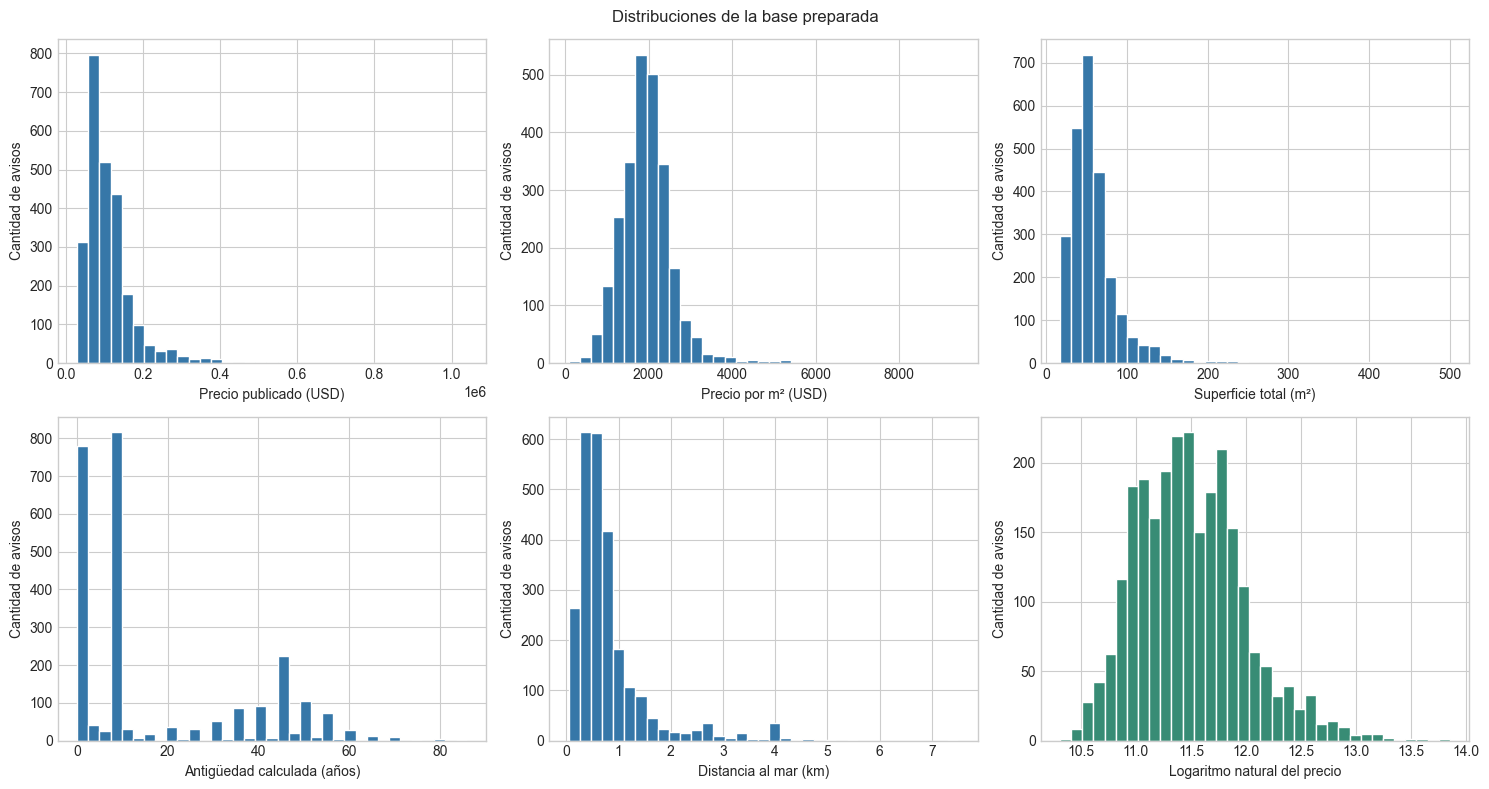

Cinco precios por m² más bajos:


,barrio,precio,superficie_total_m2,precio_usd_m2,ambientes
365,Fray Luis Beltrán,35000,400.00,87.50,2
1441,Faro Norte,79000,450.00,175.56,3
1915,Los Andes,70000,224.00,312.50,2
1007,Estación Norte,135000,400.00,337.50,2
1742,La Perla,199000,500.00,398.00,2


Cinco precios por m² más altos:


,barrio,precio,superficie_total_m2,precio_usd_m2,ambientes
1238,La Perla,480000,51.00,"9,411.76",4
2117,Faro Norte,340000,51.00,"6,666.67",3
1343,Centro,127000,20.00,"6,350.00",2
147,Rivadavia Bernardino,463000,86.00,"5,383.72",2
738,San Carlos,270000,51.00,"5,294.12",3


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
distribuciones = [
    ('precio', 'Precio publicado (USD)'),
    ('precio_usd_m2', 'Precio por m² (USD)'),
    ('superficie_total_m2', 'Superficie total (m²)'),
    ('antiguedad_calculada', 'Antigüedad calculada (años)'),
    ('distancia_al_mar_km', 'Distancia al mar (km)')
]
for ax, (columna, etiqueta) in zip(axes.flat, distribuciones):
    ax.hist(datos_eda[columna].dropna(), bins=35, color='#3677a8', edgecolor='white')
    ax.set_xlabel(etiqueta)
    ax.set_ylabel('Cantidad de avisos')
axes[1, 2].hist(np.log(datos_eda['precio']), bins=35, color='#388c75', edgecolor='white')
axes[1, 2].set_xlabel('Logaritmo natural del precio')
axes[1, 2].set_ylabel('Cantidad de avisos')
fig.suptitle('Distribuciones de la base preparada')
fig.tight_layout()
plt.show()

columnas_revision = ['barrio', 'precio', 'superficie_total_m2', 'precio_usd_m2', 'ambientes']
print('Cinco precios por m² más bajos:')
display(datos_eda.nsmallest(5, 'precio_usd_m2')[columnas_revision])
print('Cinco precios por m² más altos:')
display(datos_eda.nlargest(5, 'precio_usd_m2')[columnas_revision])


## 2.4 Reviso las categorías y la composición de la muestra

Cuento los avisos por categoría para conocer qué grupos tienen mayor presencia en la muestra.

,variable,categoria,avisos,porcentaje
0,estado,Normal,759,30.05
1,estado,No informado,587,23.24
2,estado,Reciclado,488,19.32
3,estado,Excelente,341,13.50
4,estado,A estrenar,165,6.53
5,estado,Bueno,86,3.40
6,estado,Original,61,2.41
7,estado,Muy bueno,32,1.27
8,estado,En construcción,5,0.20
9,estado,A reciclar,2,0.08


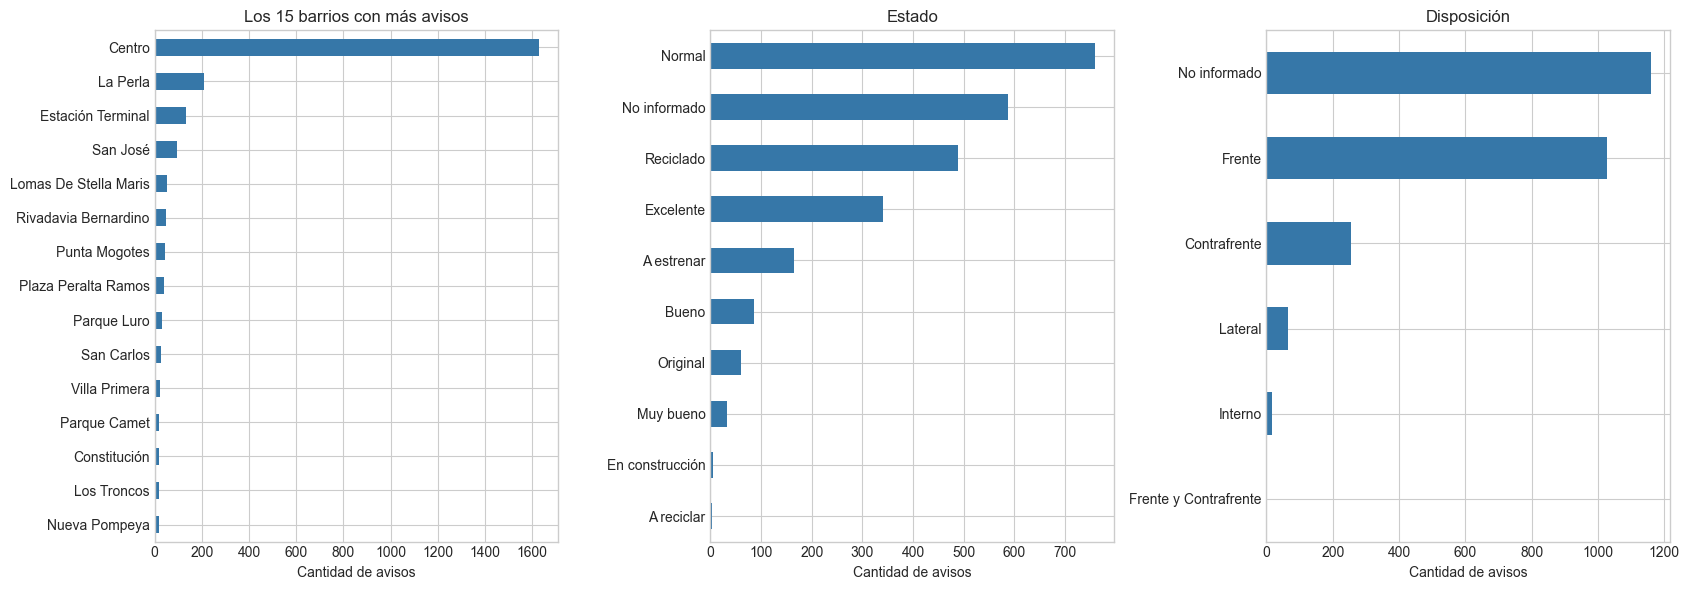

In [2]:
categoricas_eda = datos_eda.select_dtypes(exclude='number').columns
tablas_categoricas = []
for columna in categoricas_eda:
    conteo = datos_eda[columna].value_counts(dropna=False)
    tabla = conteo.rename_axis('categoria').reset_index(name='avisos')
    tabla.insert(0, 'variable', columna)
    tabla['porcentaje'] = tabla['avisos'] / len(datos_eda) * 100
    tablas_categoricas.append(tabla)
frecuencias_eda = pd.concat(tablas_categoricas, ignore_index=True)
display(frecuencias_eda.loc[frecuencias_eda['variable'].ne('barrio')])

fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, columna, titulo in zip(axes, ['barrio', 'estado', 'disposicion'],
                               ['Los 15 barrios con más avisos', 'Estado', 'Disposición']):
    datos_eda[columna].value_counts(dropna=False).head(15).sort_values().plot.barh(
        ax=ax, color='#3677a8')
    ax.set_title(titulo)
    ax.set_xlabel('Cantidad de avisos')
    ax.set_ylabel('')
fig.tight_layout()
plt.show()


## 2.5 Analizo las correlaciones entre las variables numéricas

Uso Spearman para observar cómo se relacionan el precio y las variables numéricas. Excluyo el precio por m² y la valorización porque se calcularon usando el precio.

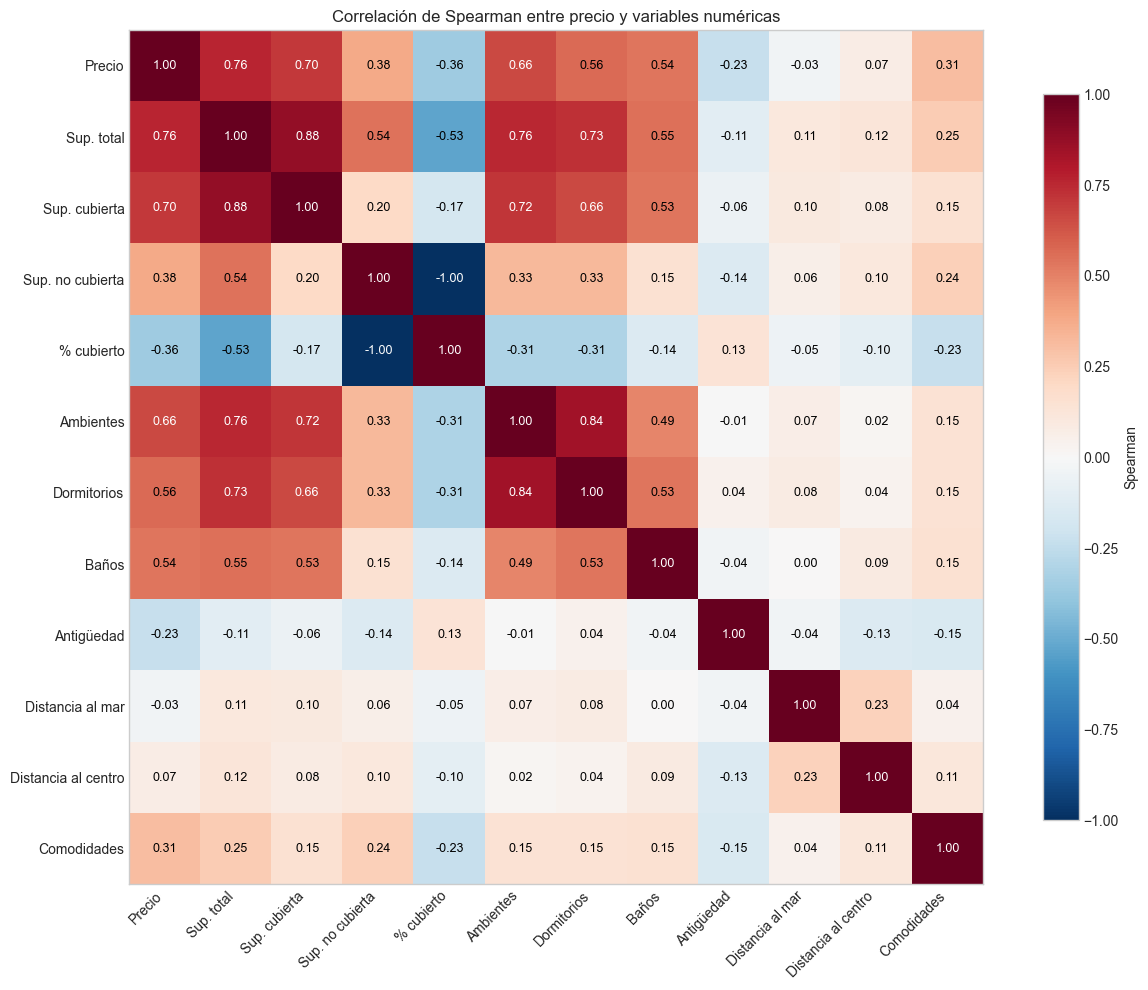

,Spearman con el precio
superficie_total_m2,0.76
superficie_cubierta_m2,0.70
ambientes,0.66
dormitorios,0.56
banos,0.54
superficie_no_cubierta_m2,0.38
porcentaje_cubierto,-0.36
cantidad_comodidades,0.31
antiguedad_calculada,-0.23
distancia_al_centro_km,0.07


In [2]:
variables_correlacion_eda = [
    'precio', 'superficie_total_m2', 'superficie_cubierta_m2',
    'superficie_no_cubierta_m2', 'porcentaje_cubierto', 'ambientes',
    'dormitorios', 'banos', 'antiguedad_calculada',
    'distancia_al_mar_km', 'distancia_al_centro_km', 'cantidad_comodidades'
]
etiquetas_correlacion_eda = [
    'Precio', 'Sup. total', 'Sup. cubierta', 'Sup. no cubierta', '% cubierto',
    'Ambientes', 'Dormitorios', 'Baños', 'Antigüedad',
    'Distancia al mar', 'Distancia al centro', 'Comodidades'
]
matriz_correlacion_eda = datos_eda[variables_correlacion_eda].corr(method='spearman')

fig, ax = plt.subplots(figsize=(13, 10))
paleta_correlacion_eda = plt.get_cmap('RdBu_r').copy()
paleta_correlacion_eda.set_bad('#eeeeee')
imagen_correlacion_eda = ax.imshow(matriz_correlacion_eda, cmap=paleta_correlacion_eda, vmin=-1, vmax=1)
ax.set_xticks(range(len(variables_correlacion_eda)), labels=etiquetas_correlacion_eda,
              rotation=45, ha='right')
ax.set_yticks(range(len(variables_correlacion_eda)), labels=etiquetas_correlacion_eda)
ax.grid(False)
for i in range(len(variables_correlacion_eda)):
    for j in range(len(variables_correlacion_eda)):
        valor = matriz_correlacion_eda.iloc[i, j]
        if pd.notna(valor):
            ax.text(j, i, f'{valor:.2f}', ha='center', va='center', fontsize=9,
                    color='white' if abs(valor) > .6 else 'black')
ax.set_title('Correlación de Spearman entre precio y variables numéricas')
fig.colorbar(imagen_correlacion_eda, ax=ax, label='Spearman', shrink=.85)
fig.tight_layout()
plt.show()

# Ordeno por fuerza de asociación y conservo el signo de la correlación.
correlaciones_precio_eda = matriz_correlacion_eda['precio'].drop('precio')
correlaciones_precio_eda = correlaciones_precio_eda.loc[
    correlaciones_precio_eda.abs().sort_values(ascending=False).index]
display(correlaciones_precio_eda.rename('Spearman con el precio').to_frame())


## 2.6 Relaciono el precio con las características del departamento

Comparo el precio con la superficie, la antigüedad, las distancias, las comodidades y los ambientes para identificar patrones generales.

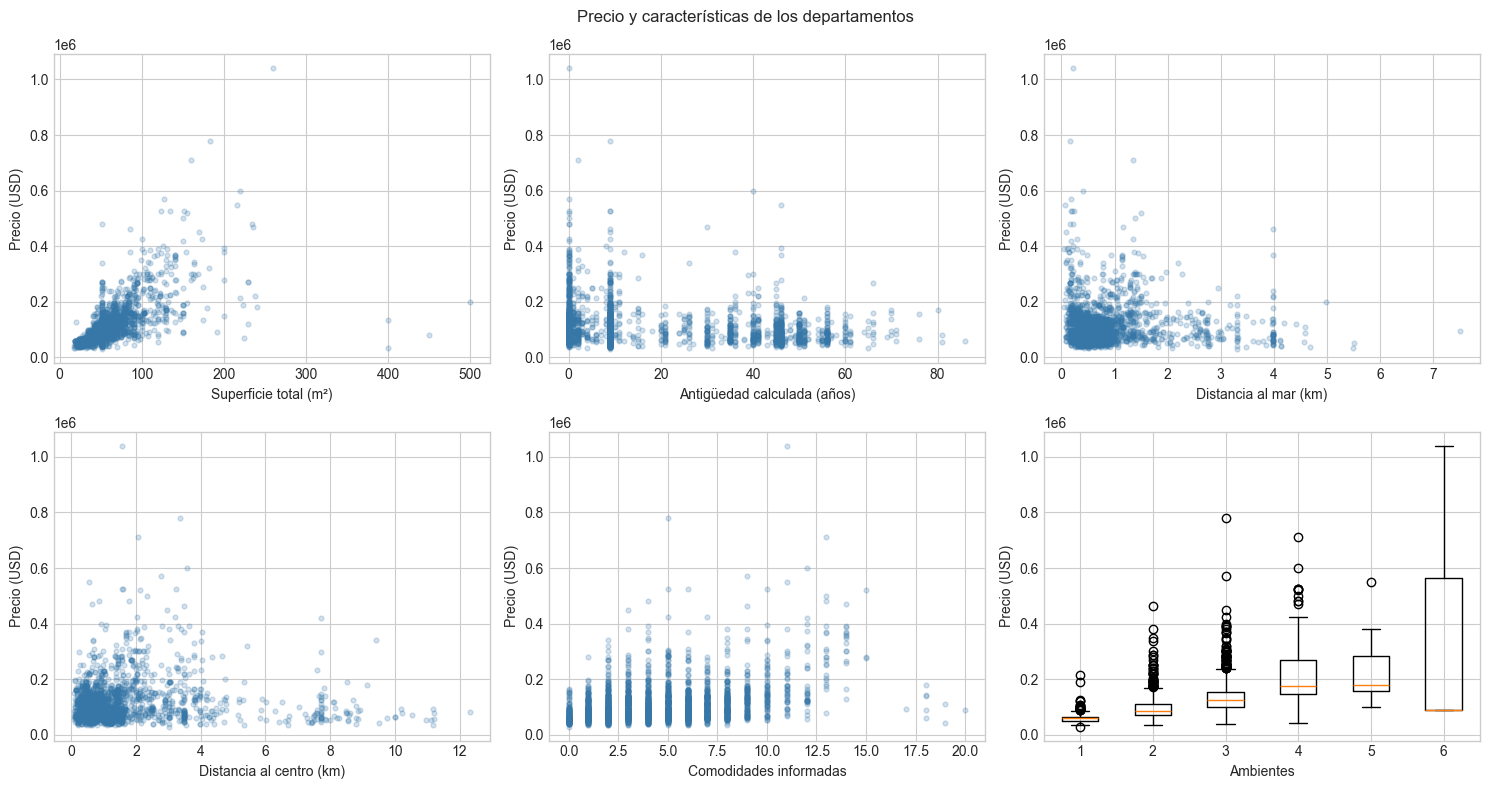

,avisos,mediana_precio_usd,mediana_superficie_m2,mediana_precio_usd_m2
ambientes,,,,
1,421,"59,500.00",30.00,"2,000.00"
2,1130,"86,900.00",48.00,"1,921.04"
3,814,"123,900.00",68.00,"1,882.61"
4,146,"176,800.00",110.00,"1,827.59"
5,12,"181,000.00",146.00,"1,509.86"
6,3,"90,000.00",150.00,600.00


In [5]:
relaciones_eda = [
    ('superficie_total_m2', 'Superficie total (m²)'),
    ('antiguedad_calculada', 'Antigüedad calculada (años)'),
    ('distancia_al_mar_km', 'Distancia al mar (km)'),
    ('distancia_al_centro_km', 'Distancia al centro (km)'),
    ('cantidad_comodidades', 'Comodidades informadas')
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (columna, etiqueta) in zip(axes.flat, relaciones_eda):
    ax.scatter(datos_eda[columna], datos_eda['precio'], alpha=.22, s=12, color='#3677a8')
    ax.set_xlabel(etiqueta)
    ax.set_ylabel('Precio (USD)')
grupos_ambientes = list(datos_eda.groupby('ambientes', sort=True))
axes[1, 2].boxplot([grupo['precio'].to_numpy() for _, grupo in grupos_ambientes])
axes[1, 2].set_xticks(range(1, len(grupos_ambientes) + 1),
                     labels=[str(valor) for valor, _ in grupos_ambientes])
axes[1, 2].set_xlabel('Ambientes')
axes[1, 2].set_ylabel('Precio (USD)')
fig.suptitle('Precio y características de los departamentos')
fig.tight_layout()
plt.show()
display(datos_eda.groupby('ambientes').agg(
    avisos=('precio', 'size'), mediana_precio_usd=('precio', 'median'),
    mediana_superficie_m2=('superficie_total_m2', 'median'),
    mediana_precio_usd_m2=('precio_usd_m2', 'median')))


## 2.7 Comparo los barrios y el nivel de valorización

Comparo las medianas por barrio y grafico los 15 con mayor precio mediano por m² para observar diferencias de valorización.

,avisos,mediana_precio_usd,mediana_precio_usd_m2,porcentaje_avisos
barrio,,,,
Playa Grande,1,"220,000.00","4,400.00",0.04
Leandro N. Alem,14,"286,625.00","3,538.41",0.55
Varese,3,"250,000.00","3,026.32",0.12
Los Troncos,18,"216,500.00","2,624.02",0.71
Constitución,18,"167,500.00","2,554.58",0.71
Lomas De Stella Maris,54,"165,000.00","2,522.73",2.14
Parque Luro,32,"149,950.00","2,336.88",1.27
Estación Terminal,132,"91,162.00","2,095.03",5.23
San José,94,"137,844.00","2,066.73",3.72


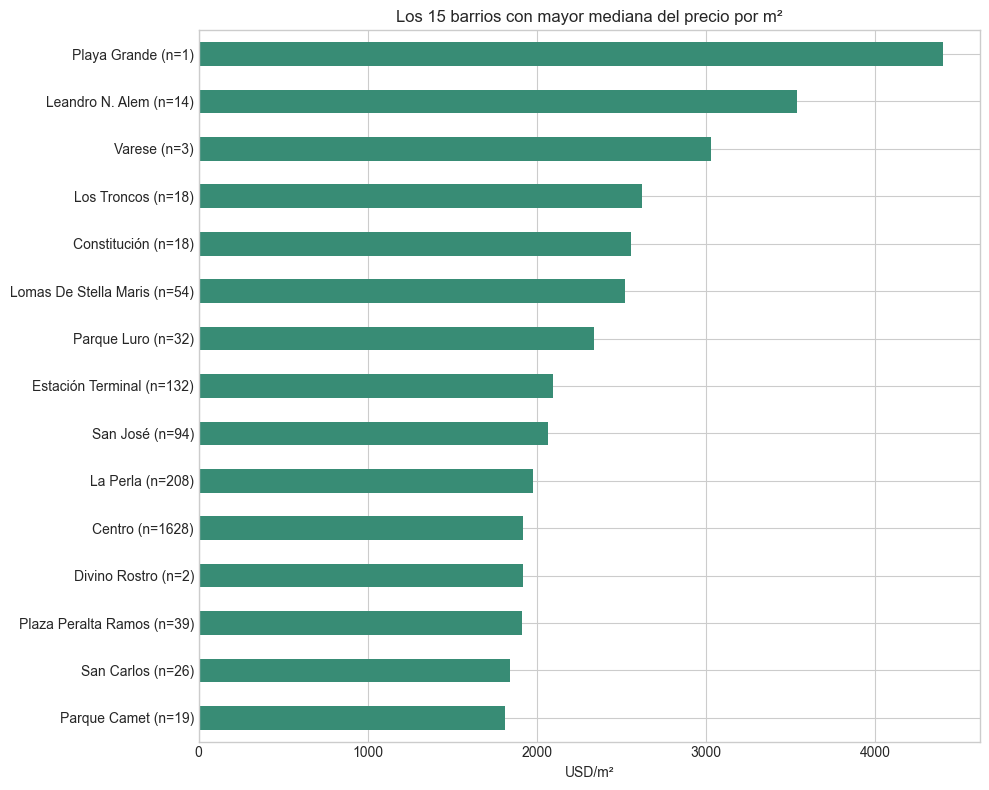

,avisos,barrios,mediana_precio_usd_m2
nivel_valorizacion_barrio,,,
Baja,113,17,"1,106.38"
Media,70,15,"1,464.44"
Alta,2343,17,"1,954.55"


In [3]:
resumen_barrios_eda = datos_eda.groupby('barrio').agg(
    avisos=('precio', 'size'), mediana_precio_usd=('precio', 'median'),
    mediana_precio_usd_m2=('precio_usd_m2', 'median'))
resumen_barrios_eda['porcentaje_avisos'] = resumen_barrios_eda['avisos'] / len(datos_eda) * 100
display(resumen_barrios_eda.sort_values('mediana_precio_usd_m2', ascending=False))
barrios_grafico = resumen_barrios_eda.nlargest(15, 'mediana_precio_usd_m2').sort_values('mediana_precio_usd_m2')
fig, ax = plt.subplots(figsize=(10, 8))
barrios_grafico['mediana_precio_usd_m2'].plot.barh(ax=ax, color='#388c75')
ax.set_yticklabels([f'{barrio} (n={int(fila.avisos)})'
                    for barrio, fila in barrios_grafico.iterrows()])
ax.set_title('Los 15 barrios con mayor mediana del precio por m²')
ax.set_xlabel('USD/m²')
ax.set_ylabel('')
fig.tight_layout()
plt.show()
display(datos_eda.groupby('nivel_valorizacion_barrio').agg(
    avisos=('precio', 'size'), barrios=('barrio', 'nunique'),
    mediana_precio_usd_m2=('precio_usd_m2', 'median')).reindex(['Baja', 'Media', 'Alta']))


## 2.8 Comparo el precio por características estructurales categóricas

Comparo el precio por estado, disposición y balcón para observar diferencias entre categorías. Muestro la cantidad de avisos y uso escala logarítmica.

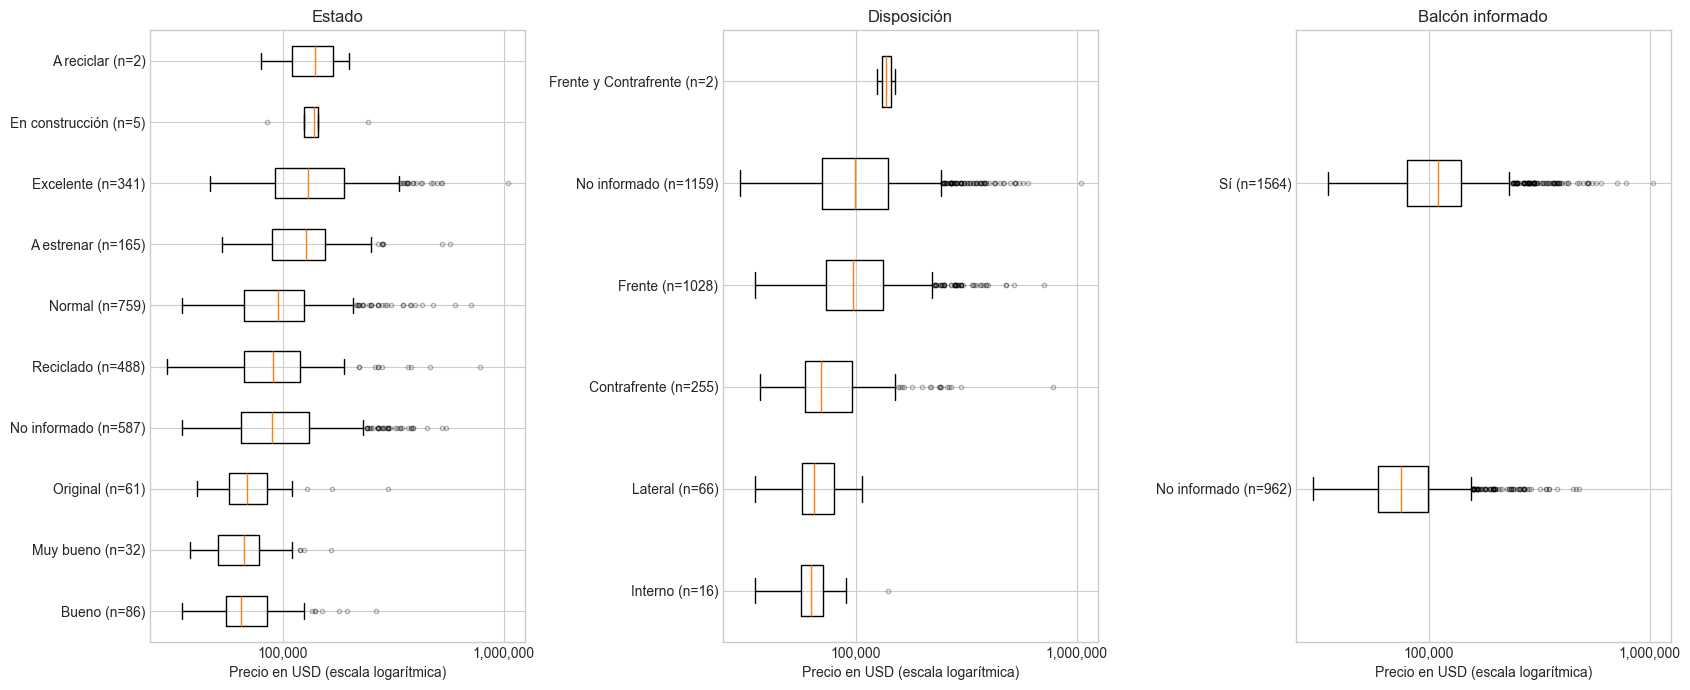

,variable,categoria,avisos,mediana_precio_usd,mediana_superficie_m2,mediana_precio_usd_m2
0,estado,Bueno,86,"65,000.00",51.00,"1,381.94"
1,estado,Muy bueno,32,"67,000.00",51.00,"1,455.77"
2,estado,Original,61,"69,000.00",49.00,"1,547.62"
3,estado,No informado,587,"88,900.00",51.00,"1,803.28"
4,estado,Reciclado,488,"89,900.00",51.00,"1,927.36"
5,estado,Normal,759,"95,000.00",51.00,"1,927.59"
6,estado,A estrenar,165,"126,900.00",51.00,"2,132.43"
7,estado,Excelente,341,"130,000.00",60.00,"2,211.90"
8,estado,En construcción,5,"139,000.00",69.00,"2,014.49"
9,estado,A reciclar,2,"139,450.00",280.00,864.83


In [7]:
from matplotlib.ticker import FuncFormatter

fig, axes = plt.subplots(1, 3, figsize=(17, 7))
tablas_cruces = []
for ax, columna, titulo in zip(axes, ['estado', 'disposicion', 'tiene_balcon'],
                               ['Estado', 'Disposición', 'Balcón informado']):
    tabla = datos_eda.groupby(columna, dropna=False).agg(
        avisos=('precio', 'size'), mediana_precio_usd=('precio', 'median'),
        mediana_superficie_m2=('superficie_total_m2', 'median'),
        mediana_precio_usd_m2=('precio_usd_m2', 'median')
    ).sort_values('mediana_precio_usd')
    grupos = [datos_eda.loc[datos_eda[columna].eq(c), 'precio'].to_numpy()
              for c in tabla.index]
    ax.boxplot(grupos, vert=False, flierprops={'markersize': 3, 'alpha': .3})
    ax.set_yticks(range(1, len(tabla) + 1),
                  labels=[f'{c} (n={n})' for c, n in tabla['avisos'].items()])
    ax.set_xscale('log')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:,.0f}'))
    ax.set_xlabel('Precio en USD (escala logarítmica)')
    ax.set_title(titulo)
    tablas_cruces.append(tabla.rename_axis('categoria').assign(variable=columna).reset_index())
fig.tight_layout()
plt.show()
resumen_cruces_categoricos = pd.concat(tablas_cruces, ignore_index=True)
display(resumen_cruces_categoricos[['variable', 'categoria', 'avisos',
    'mediana_precio_usd', 'mediana_superficie_m2', 'mediana_precio_usd_m2']])


## 2.9 Relaciono las características estructurales con el precio por barrio - H1

Comparo las características estructurales y el precio en los 15 barrios con más avisos para revisar si su relación cambia según la ubicación. Uso correlaciones y medianas, en los gráficos muestro resultados desde cinco casos e identifico los grupos más pequeños.

Correlación de Spearman con el precio dentro de cada barrio:


,avisos,superficie_total_m2,superficie_cubierta_m2,superficie_no_cubierta_m2,porcentaje_cubierto,ambientes,dormitorios,banos,antiguedad_calculada
barrio,,,,,,,,,
Centro,1628,0.82,0.77,0.38,-0.37,0.75,0.65,0.49,-0.15
La Perla,208,0.70,0.65,0.29,-0.27,0.57,0.50,0.58,-0.25
Estación Terminal,132,0.85,0.79,0.63,-0.58,0.68,0.64,0.63,-0.42
San José,94,0.75,0.61,0.41,-0.36,0.49,0.54,0.59,-0.36
Lomas De Stella Maris,54,0.87,0.65,0.42,-0.41,0.72,0.65,0.67,-0.40
Rivadavia Bernardino,48,0.71,0.85,-0.14,0.17,0.56,0.36,0.59,-0.35
Punta Mogotes,44,0.71,0.53,0.22,-0.21,0.48,0.48,0.69,-0.13
Plaza Peralta Ramos,39,0.54,0.59,0.02,0.03,0.40,0.25,0.60,-0.39
Parque Luro,32,0.73,0.54,0.39,-0.35,0.51,0.53,0.30,-0.27


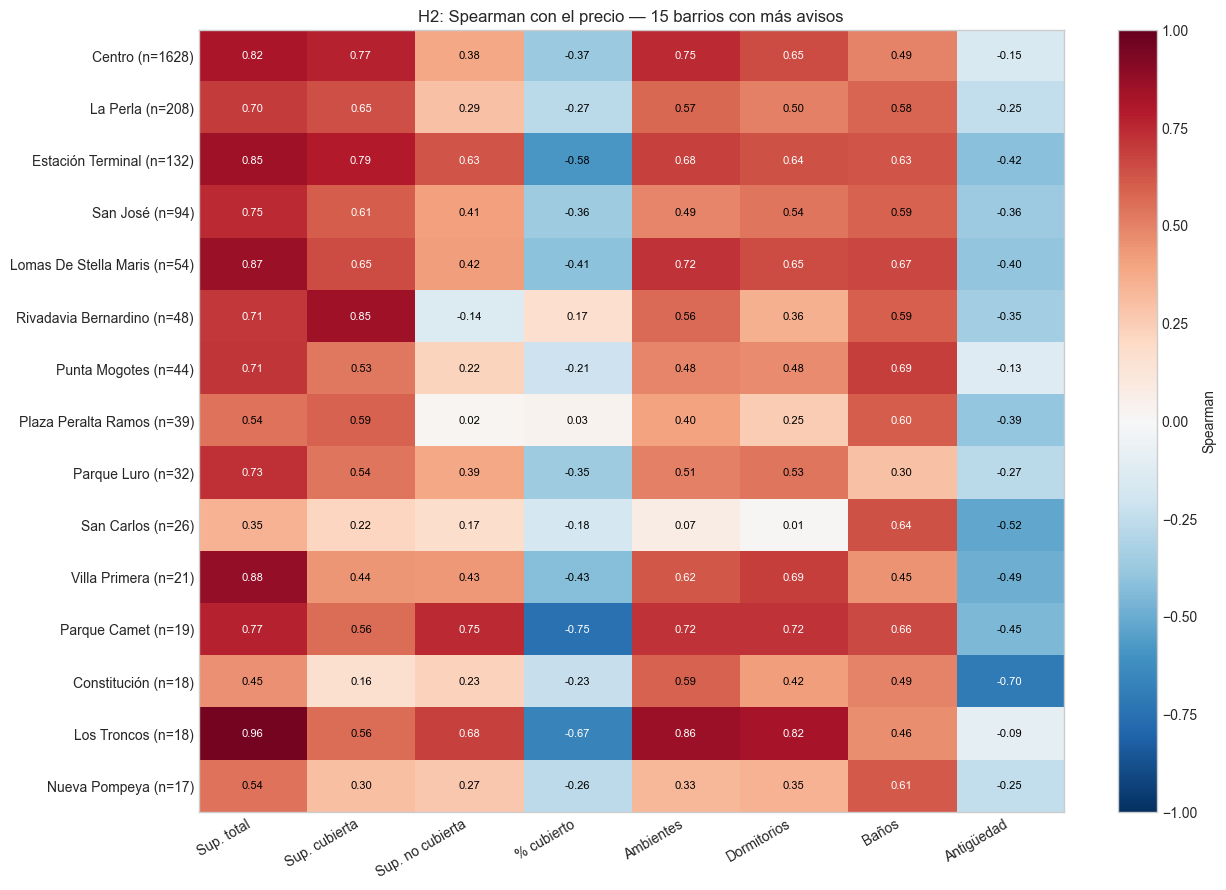

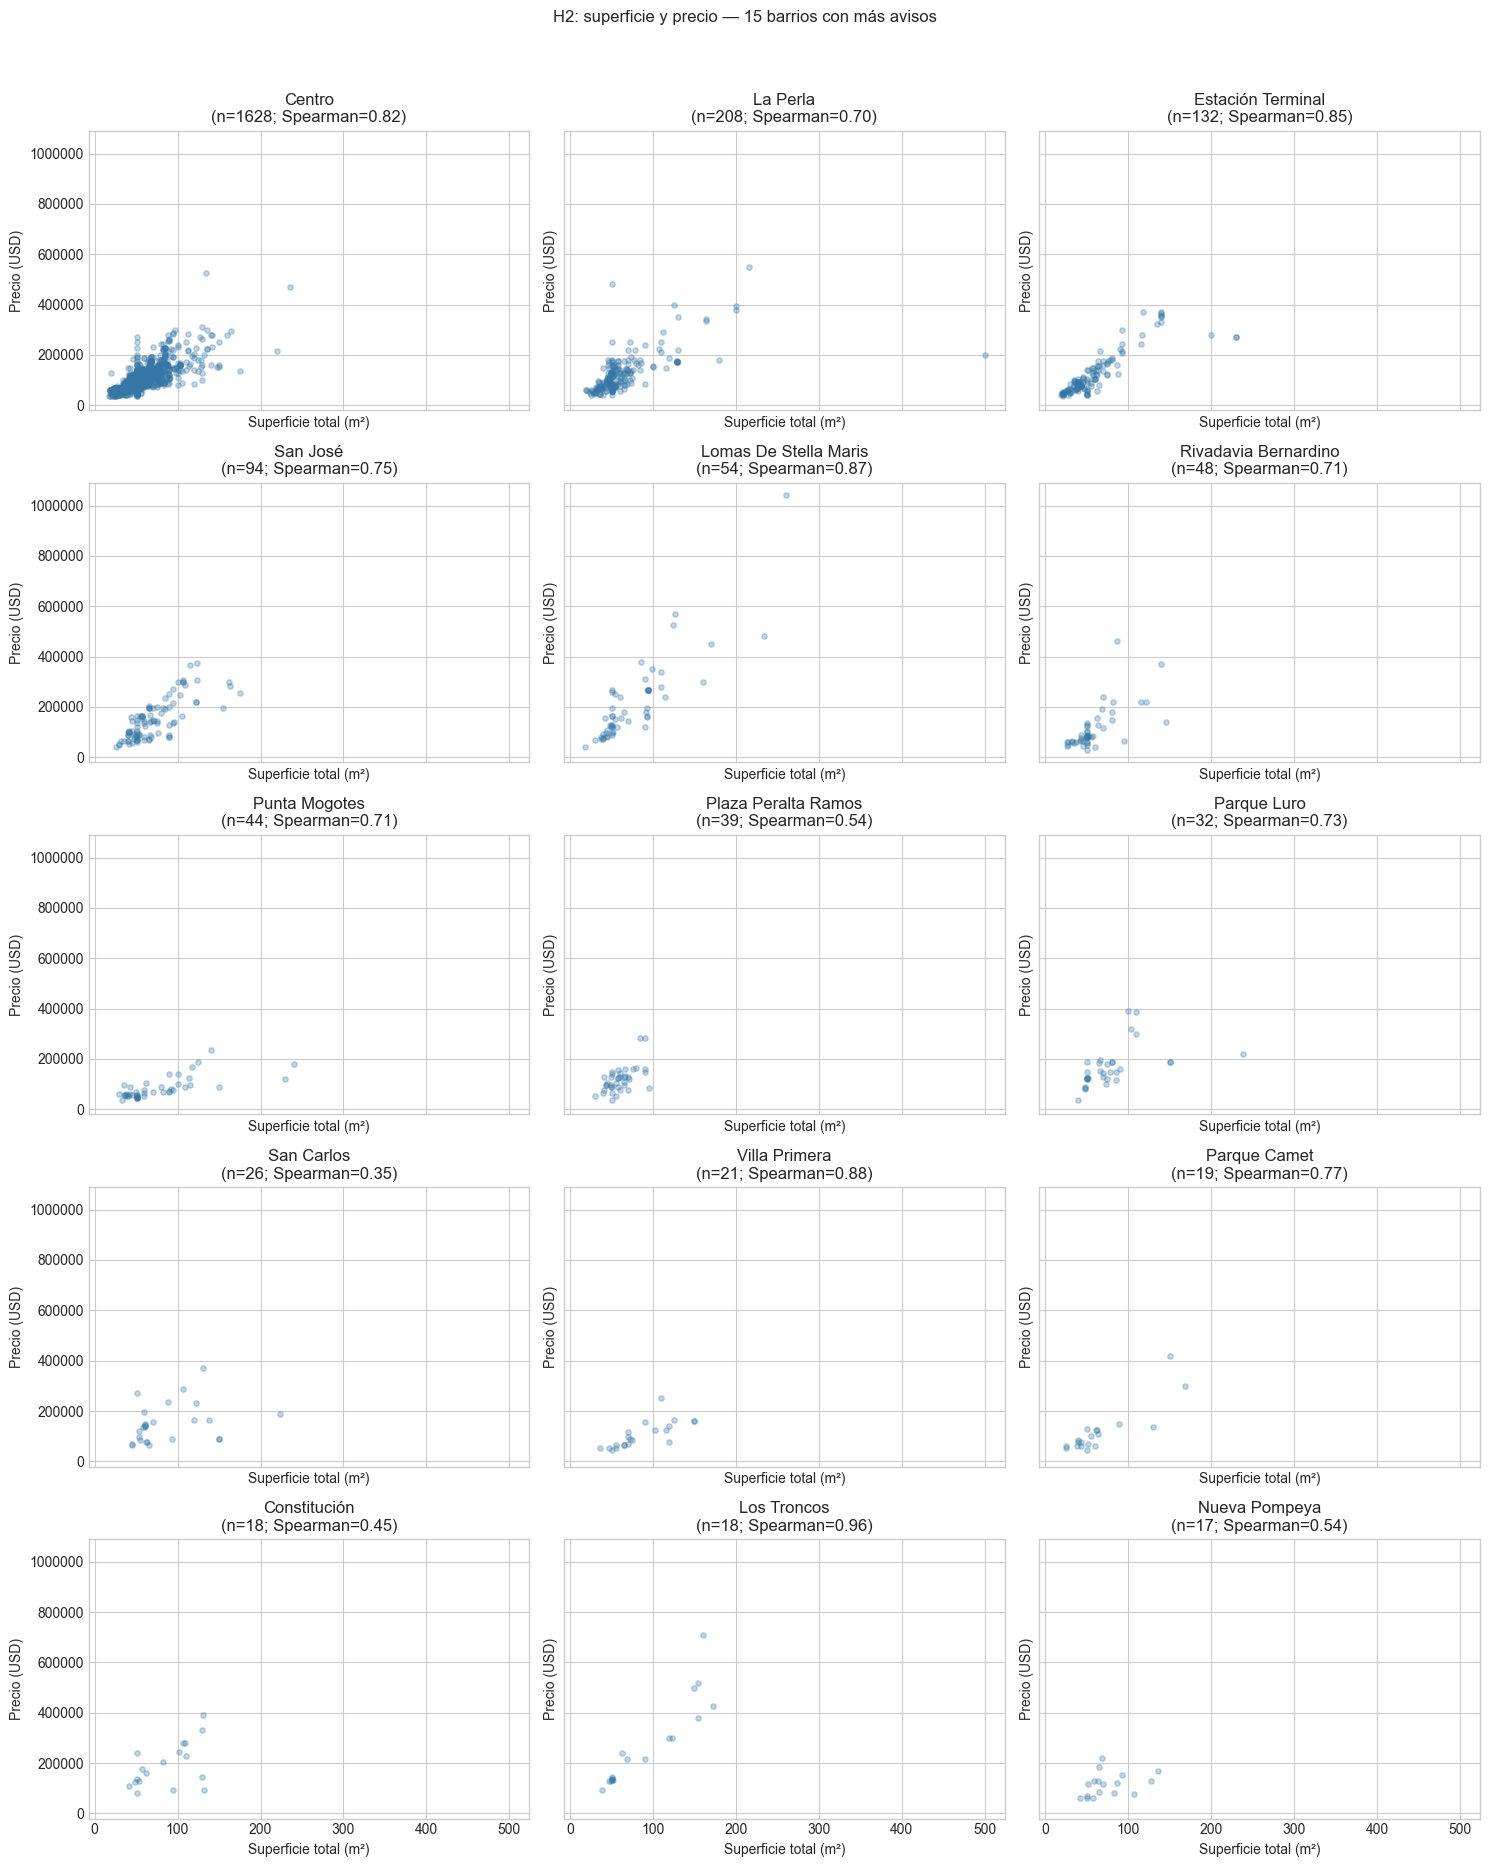

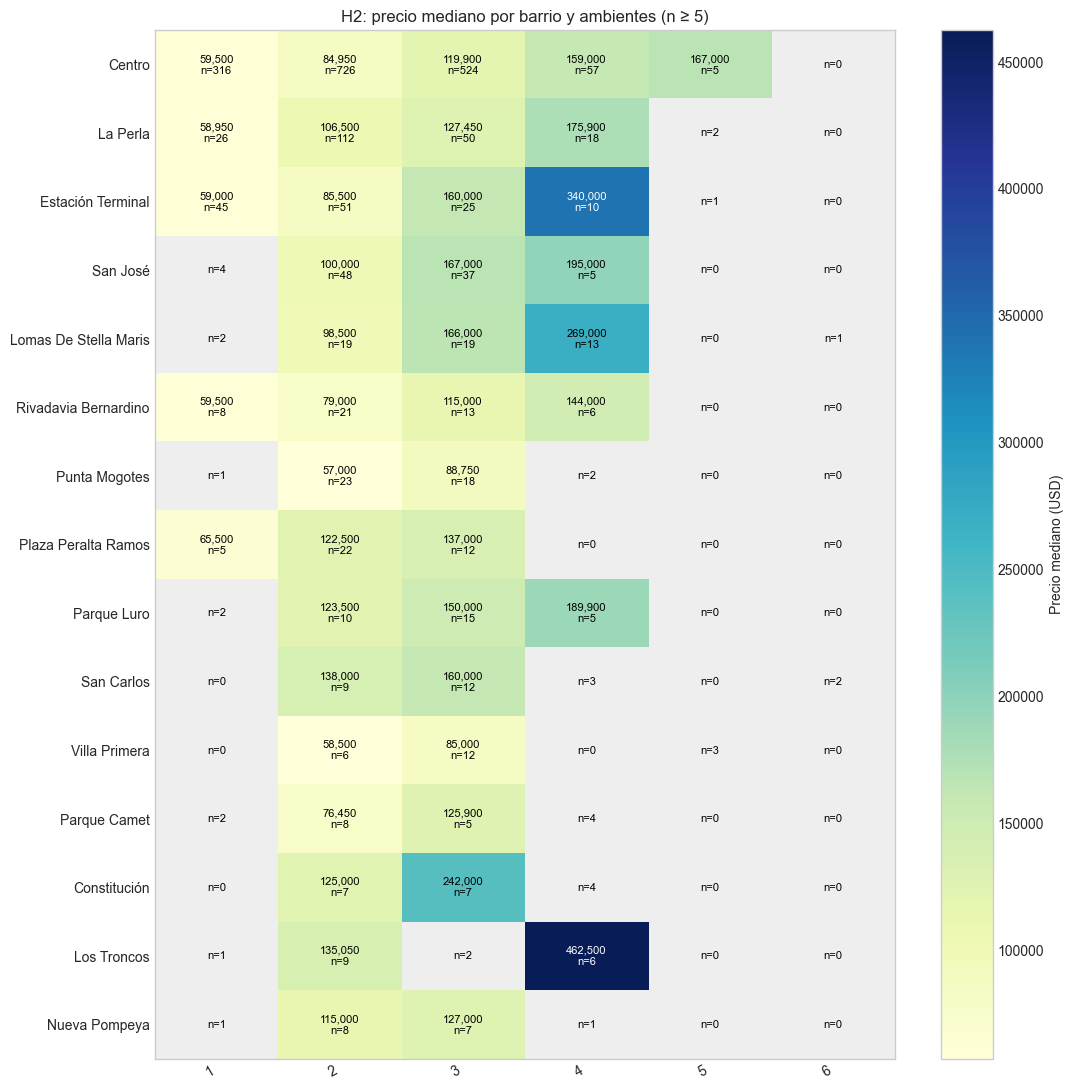

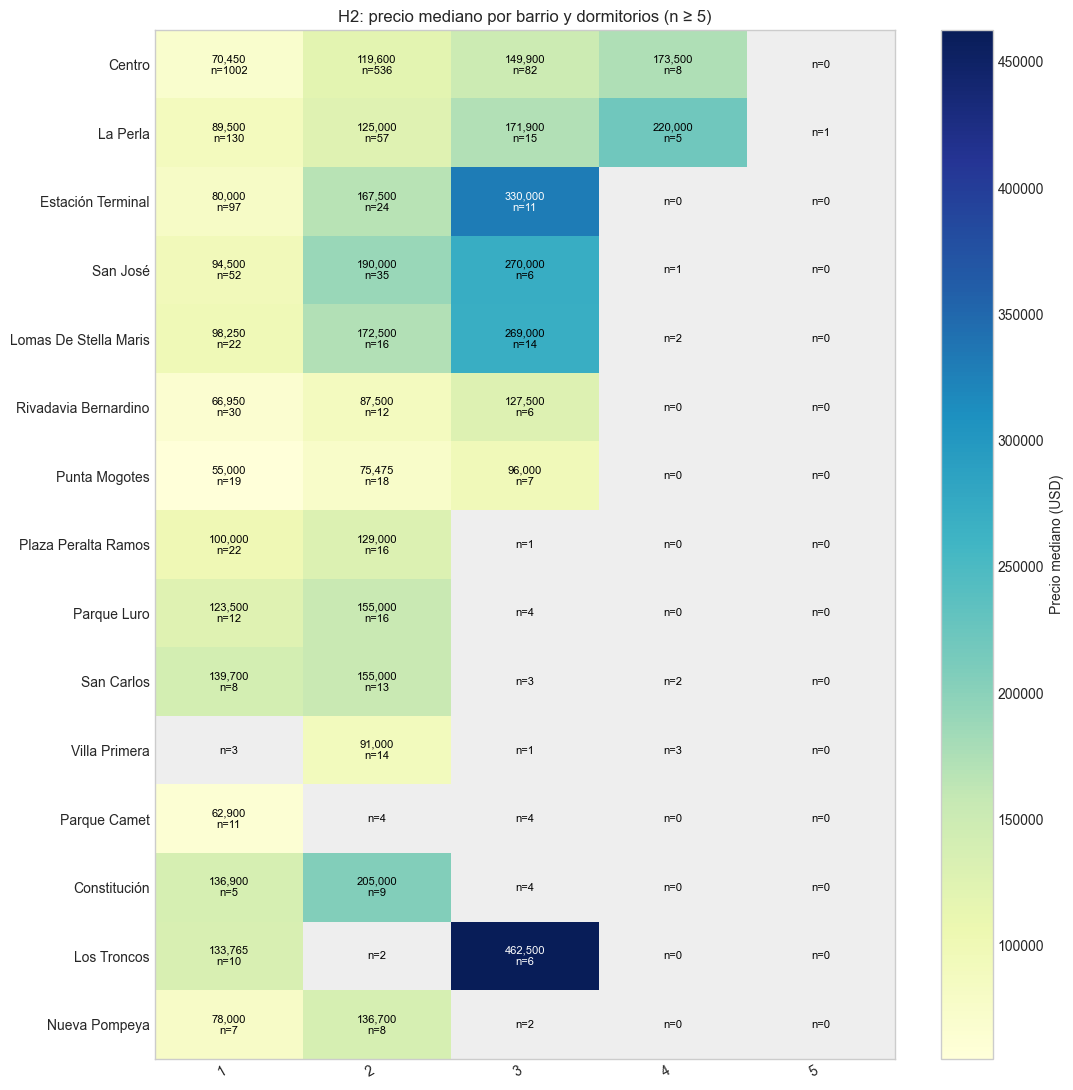

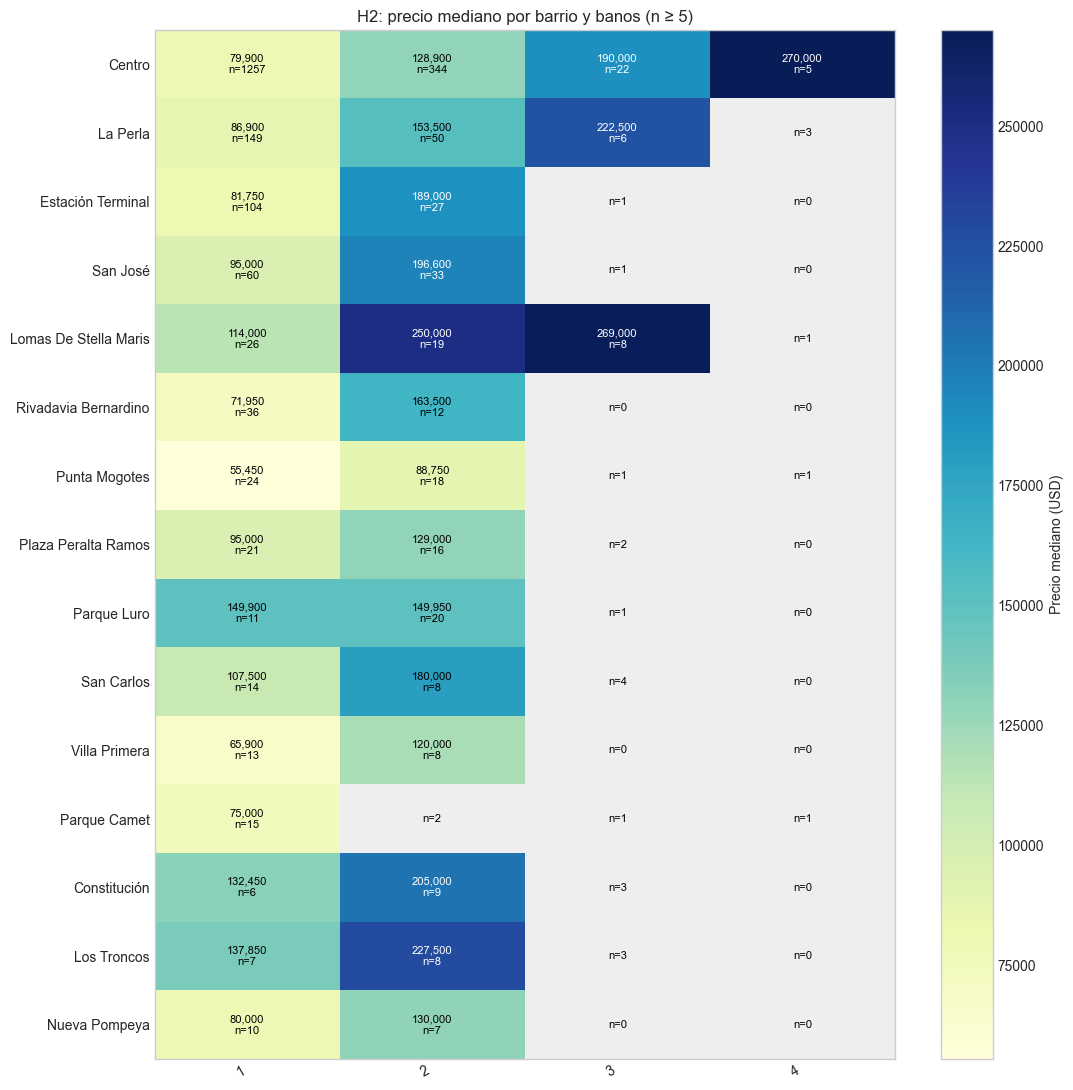

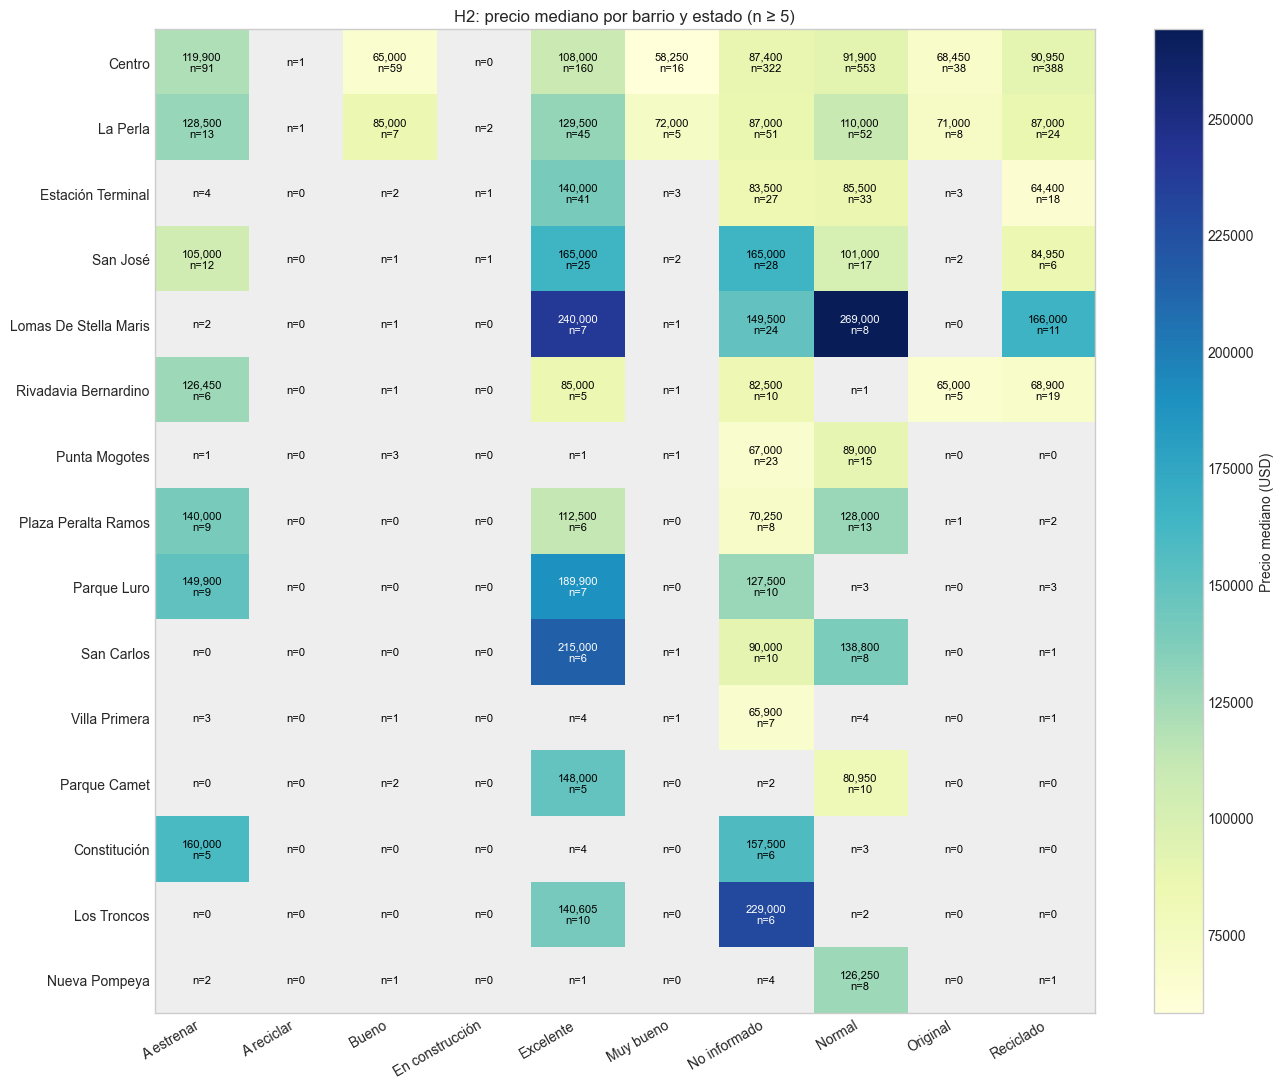

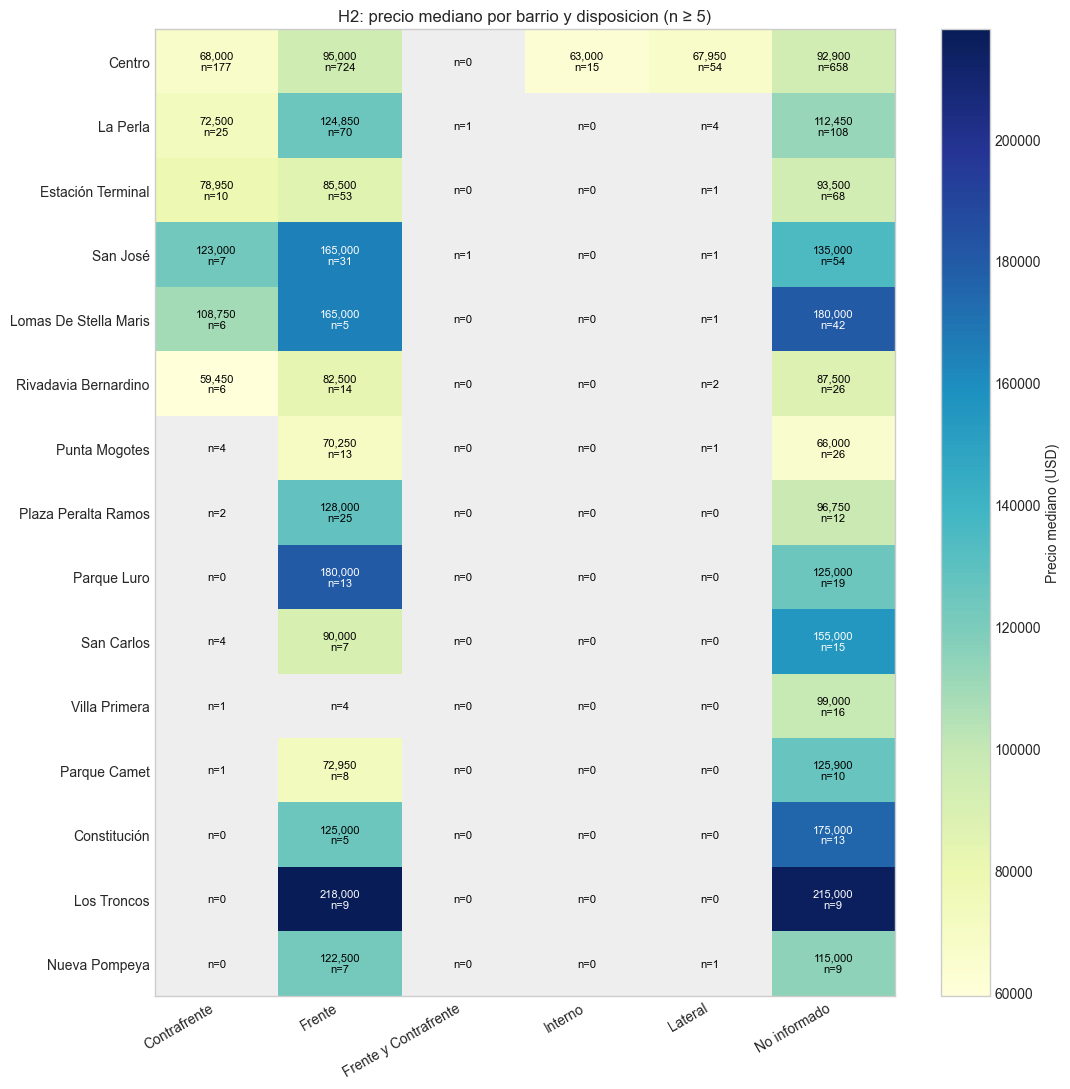

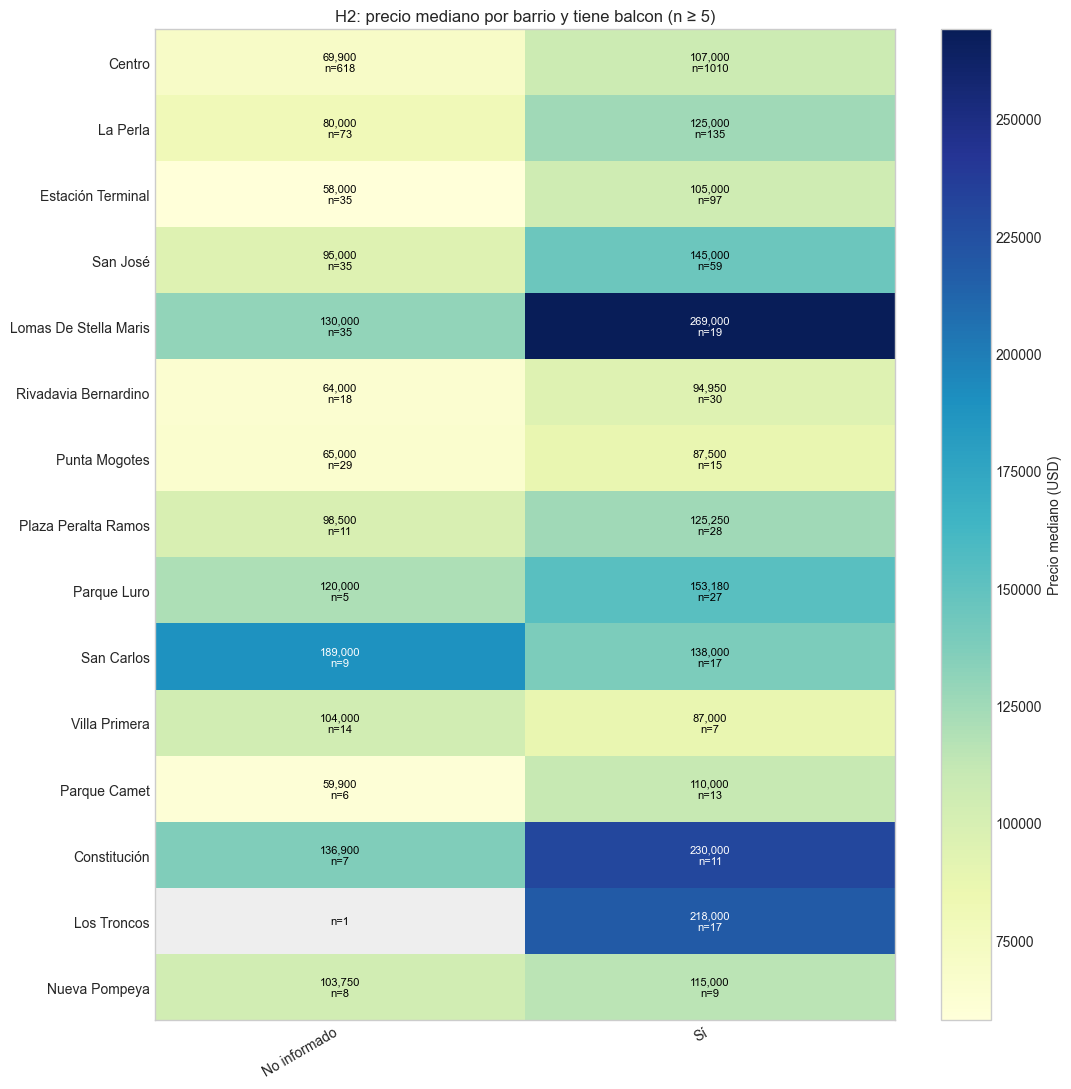

Cruce completo: barrio y ambientes


,barrio,categoria,avisos,mediana_precio_usd,mediana_superficie_m2
0,Centro,1,316,"59,500.00",28.00
1,Centro,2,726,"84,950.00",44.00
2,Centro,3,524,"119,900.00",66.00
3,Centro,4,57,"159,000.00",90.00
4,Centro,5,5,"167,000.00",136.00
5,La Perla,1,26,"58,950.00",34.00
6,La Perla,2,112,"106,500.00",50.00
7,La Perla,3,50,"127,450.00",66.00
8,La Perla,4,18,"175,900.00",129.00
9,La Perla,5,2,"465,000.00",208.00


Cruce completo: barrio y dormitorios


,barrio,categoria,avisos,mediana_precio_usd,mediana_superficie_m2
0,Centro,1,1002,"70,450.00",40.00
1,Centro,2,536,"119,600.00",66.00
2,Centro,3,82,"149,900.00",87.00
3,Centro,4,8,"173,500.00",125.00
4,La Perla,1,130,"89,500.00",48.00
5,La Perla,2,57,"125,000.00",67.00
6,La Perla,3,15,"171,900.00",129.00
7,La Perla,4,5,"220,000.00",130.00
8,La Perla,5,1,"550,000.00",216.00
9,Estación Terminal,1,97,"80,000.00",41.00


Cruce completo: barrio y banos


...

,barrio,categoria,avisos,mediana_precio_usd,mediana_superficie_m2
0,Centro,A estrenar,91,"119,900.00",51.00
1,Centro,A reciclar,1,"79,900.00",60.00
2,Centro,Bueno,59,"65,000.00",50.00
3,Centro,Excelente,160,"108,000.00",53.00
4,Centro,Muy bueno,16,"58,250.00",39.00
5,Centro,No informado,322,"87,400.00",51.00
6,Centro,Normal,553,"91,900.00",50.00
7,Centro,Original,38,"68,450.00",41.00
8,Centro,Reciclado,388,"90,950.00",51.00
9,La Perla,A estrenar,13,"128,500.00",51.00


Cruce completo: barrio y disposicion


,barrio,categoria,avisos,mediana_precio_usd,mediana_superficie_m2
0,Centro,Contrafrente,177,"68,000.00",40.00
1,Centro,Frente,724,"95,000.00",51.00
2,Centro,Interno,15,"63,000.00",40.00
3,Centro,Lateral,54,"67,950.00",37.00
4,Centro,No informado,658,"92,900.00",51.00
5,La Perla,Contrafrente,25,"72,500.00",45.00
6,La Perla,Frente,70,"124,850.00",52.00
7,La Perla,Frente y Contrafrente,1,"124,800.00",54.00
8,La Perla,Lateral,4,"61,950.00",29.00
9,La Perla,No informado,108,"112,450.00",52.50


Cruce completo: barrio y tiene_balcon


,barrio,categoria,avisos,mediana_precio_usd,mediana_superficie_m2
0,Centro,No informado,618,"69,900.00",43.00
1,Centro,Sí,1010,"107,000.00",51.50
2,La Perla,No informado,73,"80,000.00",50.00
3,La Perla,Sí,135,"125,000.00",53.00
4,Estación Terminal,No informado,35,"58,000.00",36.00
5,Estación Terminal,Sí,97,"105,000.00",51.00
6,San José,No informado,35,"95,000.00",59.00
7,San José,Sí,59,"145,000.00",66.00
8,Lomas De Stella Maris,No informado,35,"130,000.00",51.00
9,Lomas De Stella Maris,Sí,19,"269,000.00",90.00


In [ ]:
barrios_h2 = datos_eda['barrio'].value_counts().rename_axis('barrio').reset_index(name='avisos')
barrios_h2 = barrios_h2.sort_values(['avisos', 'barrio'], ascending=[False, True]).head(15)['barrio'].tolist()
estructurales_h2 = [
    'superficie_total_m2', 'superficie_cubierta_m2', 'superficie_no_cubierta_m2',
    'porcentaje_cubierto', 'ambientes', 'dormitorios', 'banos', 'antiguedad_calculada'
]
categoricas_h2 = ['estado', 'disposicion', 'tiene_balcon']
filas_h2 = []
for barrio, grupo in datos_eda.groupby('barrio'):
    grupo = datos_eda.loc[datos_eda['barrio'].eq(barrio)]
    correlaciones = grupo[estructurales_h2 + ['precio']].corr(method='spearman', min_periods=5)['precio']
    filas_h2.append({'barrio': barrio, 'avisos': len(grupo),
                     **{c: correlaciones[c] for c in estructurales_h2}})
resumen_h2 = pd.DataFrame(filas_h2).set_index('barrio')
print('Correlación de Spearman con el precio dentro de cada barrio:')
display(resumen_h2.loc[barrios_h2])

# Comparo todas las características numéricas entre los barrios más representados.
barrios_matriz_h2 = barrios_h2
matriz_h2 = resumen_h2.loc[barrios_matriz_h2, estructurales_h2]
fig, ax = plt.subplots(figsize=(13, 9))
paleta_h2 = plt.get_cmap('RdBu_r').copy()
paleta_h2.set_bad('#eeeeee')
imagen_h2 = ax.imshow(matriz_h2, vmin=-1, vmax=1, cmap=paleta_h2, aspect='auto')
ax.set_xticks(range(len(estructurales_h2)), labels=[
    'Sup. total', 'Sup. cubierta', 'Sup. no cubierta', '% cubierto',
    'Ambientes', 'Dormitorios', 'Baños', 'Antigüedad'], rotation=30, ha='right')
ax.set_yticks(range(len(barrios_matriz_h2)), labels=[
    f'{b} (n={int(resumen_h2.loc[b, "avisos"])})' for b in barrios_matriz_h2])
ax.grid(False)
for i in range(len(barrios_matriz_h2)):
    for j in range(len(estructurales_h2)):
        valor = matriz_h2.iloc[i, j]
        ax.text(j, i, f'{valor:.2f}' if pd.notna(valor) else 'N/D',
                ha='center', va='center', fontsize=8,
                color='white' if pd.notna(valor) and abs(valor) > .6 else 'black')
ax.set_title('H2: Spearman con el precio — 15 barrios con más avisos')
fig.colorbar(imagen_h2, ax=ax, label='Spearman')
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(5, 3, figsize=(15, 19), sharex=True, sharey=True)
for ax, barrio in zip(axes.flat, barrios_h2):
    grupo = datos_eda.loc[datos_eda['barrio'].eq(barrio)]
    ax.scatter(grupo['superficie_total_m2'], grupo['precio'], alpha=.3, s=15, color='#3677a8')
    rho = resumen_h2.loc[barrio, 'superficie_total_m2']
    ax.set_title(f'{barrio}\n(n={len(grupo)}; Spearman={rho:.2f})')
    ax.set_xlabel('Superficie total (m²)')
    ax.set_ylabel('Precio (USD)')
    ax.ticklabel_format(axis='y', style='plain')
fig.suptitle('H2: superficie y precio — 15 barrios con más avisos')
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Comparo las cantidades y las categorías dentro de cada barrio.
tablas_h2 = []
for columna in ['ambientes', 'dormitorios', 'banos'] + categoricas_h2:
    tabla = datos_eda.groupby(['barrio', columna], dropna=False).agg(
        avisos=('precio', 'size'), mediana_precio_usd=('precio', 'median'),
        mediana_superficie_m2=('superficie_total_m2', 'median'))
    tabla.index.names = ['barrio', 'categoria']
    tablas_h2.append(tabla.reset_index().assign(variable=columna))
    medianas = tabla['mediana_precio_usd'].unstack().reindex(barrios_h2)
    cantidades = tabla['avisos'].unstack().reindex(barrios_h2).fillna(0)
    visibles = medianas.where(cantidades.ge(5))
    paleta = plt.get_cmap('YlGnBu').copy()
    paleta.set_bad('#eeeeee')
    fig, ax = plt.subplots(figsize=(max(11, len(visibles.columns) * 1.35), 11))
    imagen = ax.imshow(visibles, aspect='auto', cmap=paleta)
    ax.set_xticks(range(len(visibles.columns)), labels=visibles.columns, rotation=30, ha='right')
    ax.set_yticks(range(len(barrios_h2)), labels=barrios_h2)
    ax.grid(False)
    for i in range(len(barrios_h2)):
        for j in range(len(visibles.columns)):
            valor = visibles.iloc[i, j]
            cantidad = int(cantidades.iloc[i, j])
            texto = f'{valor:,.0f}\nn={cantidad}' if pd.notna(valor) else f'n={cantidad}'
            ax.text(j, i, texto, ha='center', va='center', fontsize=8,
                    color='white' if pd.notna(valor) and imagen.norm(valor) > .6 else 'black')
    ax.set_title(f'H2: precio mediano por barrio y {columna.replace("_", " ")} (n ≥ 5)')
    fig.colorbar(imagen, ax=ax, label='Precio mediano (USD)')
    fig.tight_layout()
    plt.show()

resumen_categoricas_h2 = pd.concat(tablas_h2, ignore_index=True)
for columna in ['ambientes', 'dormitorios', 'banos'] + categoricas_h2:
    print(f'Cruce completo: barrio y {columna}')
    cruce = resumen_categoricas_h2.loc[resumen_categoricas_h2['variable'].eq(columna),
        ['barrio', 'categoria', 'avisos', 'mediana_precio_usd', 'mediana_superficie_m2']]
    cruce = cruce.set_index('barrio').loc[barrios_h2].reset_index()
    with pd.option_context('display.max_rows', None):
        display(cruce)


## 2.10 Relaciono superficie y precio por m² según valorización - H3

Comparo superficie y precio por m² según valorización para revisar si las propiedades pequeñas tienen mayor valor por m² en zonas de alta valorización. Uso los mismos rangos y muestro medianas en los gráficos desde cinco avisos.

,avisos,barrios,Spearman,mediana_precio_usd_m2
nivel,,,,
Baja,113,17,-0.37,"1,106.38"
Media,70,15,-0.25,"1,464.44"
Alta,2343,17,-0.13,"1,954.55"


avisos  mediana_precio_usd_m2  \
nivel_valorizacion_barrio rango_superficie                                   
Alta                      Hasta 40 m²           666               2,033.33   
                          Más de 40 a 60 m²     892               1,927.45   
                          Más de 60 a 90 m²     576               1,865.33   
                          Más de 90 m²          209               1,887.93   
Baja                      Hasta 40 m²            13               1,444.44   
                          Más de 40 a 60 m²      39               1,117.65   
                          Más de 60 a 90 m²      32               1,095.26   
                          Más de 90 m²           29                 869.57   
Media                     Hasta 40 m²             7               1,450.00   
                          Más de 40 a 60 m²      29               1,530.61   
                          Más de 60 a 90 m²      22               1,550.00   
                          Más de 90 m²           12               1,113.66   

                                             mediana_x  
nivel_valorizacion_barrio rango_superficie              
Alta                      Hasta 40 m²            32.00  
                          Más de 40 a 60 m²      51.00  
                          Más de 60 a 90 m²      70.00  
                          Más de 90 m²          120.00  
Baja                      Hasta 40 m²            36.00  
                          Más de 40 a 60 m²      51.00  
                          Más de 60 a 90 m²      75.00  
                          Más de 90 m²          120.00  
Media                     Hasta 40 m²            36.00  
                          Más de 40 a 60 m²      51.00  
                          Más de 60 a 90 m²      70.00  
                          Más de 90 m²          123.50

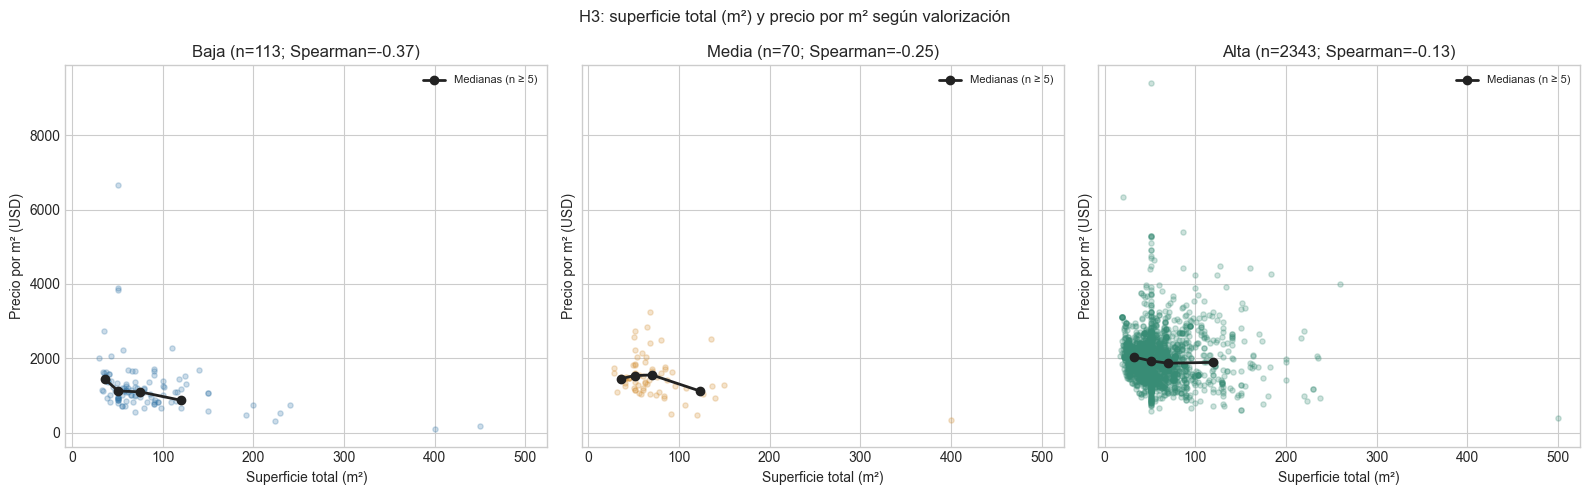

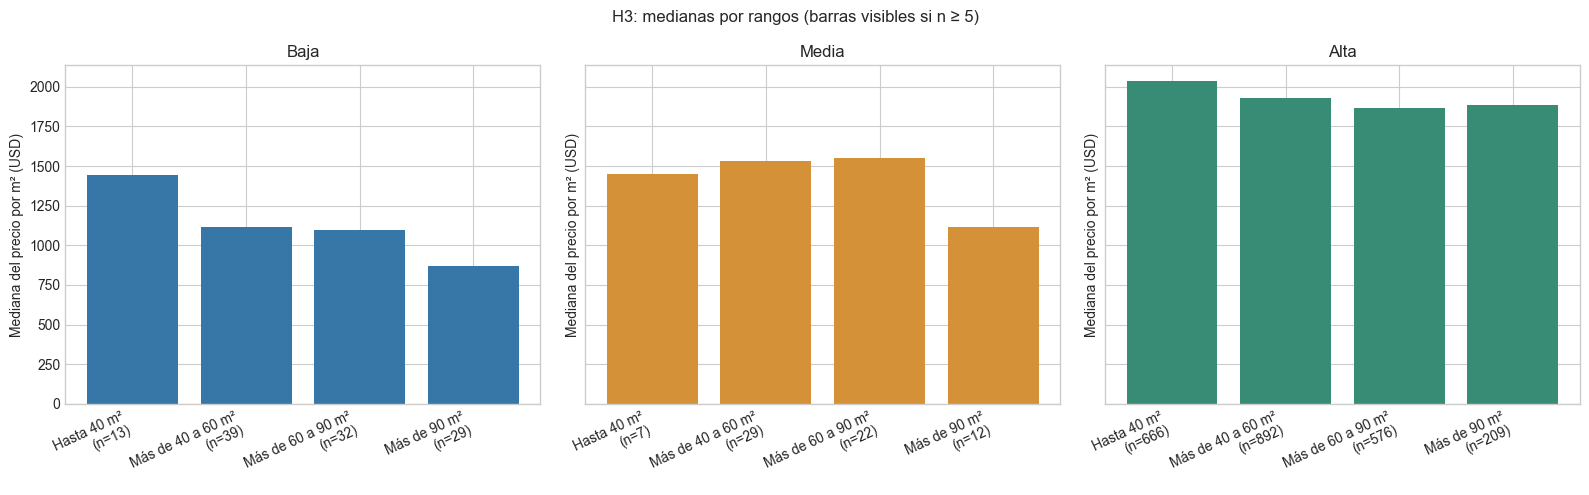

In [3]:
niveles_hipotesis = ['Baja', 'Media', 'Alta']
colores_hipotesis = ['#3677a8', '#d49137', '#388c75']
base_hipotesis = datos_eda.copy()
base_hipotesis['rango_superficie'] = pd.cut(
    base_hipotesis['superficie_total_m2'], bins=[0, 40, 60, 90, np.inf],
    labels=['Hasta 40 m²', 'Más de 40 a 60 m²', 'Más de 60 a 90 m²', 'Más de 90 m²'])

# Reutilizo estos gráficos para superficie y antigüedad.
def analizar_por_valorizacion(columna, rango, etiqueta, hipotesis):
    filas = []
    for nivel in niveles_hipotesis:
        grupo = base_hipotesis.loc[base_hipotesis['nivel_valorizacion_barrio'].eq(nivel)]
        pares = grupo[[columna, 'precio_usd_m2']].dropna()
        rho = pares.corr(method='spearman').loc[columna, 'precio_usd_m2']
        filas.append({'nivel': nivel, 'avisos': len(pares), 'barrios': grupo['barrio'].nunique(),
                       'Spearman': rho, 'mediana_precio_usd_m2': pares['precio_usd_m2'].median()})
    resumen = pd.DataFrame(filas).set_index('nivel')
    display(resumen)
    tabla = base_hipotesis.groupby(['nivel_valorizacion_barrio', rango], observed=True).agg(
        avisos=('precio_usd_m2', 'size'),
        mediana_precio_usd_m2=('precio_usd_m2', 'median'),
        mediana_x=(columna, 'median'))
    display(tabla)
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
    for ax, nivel, color in zip(axes, niveles_hipotesis, colores_hipotesis):
        grupo = base_hipotesis.loc[base_hipotesis['nivel_valorizacion_barrio'].eq(nivel)]
        ax.scatter(grupo[columna], grupo['precio_usd_m2'], color=color, alpha=.25, s=14)
        if nivel in tabla.index.get_level_values(0):
            medianas = tabla.loc[nivel].copy()
            medianas['mediana_precio_usd_m2'] = medianas['mediana_precio_usd_m2'].where(medianas['avisos'].ge(5))
            ax.plot(medianas['mediana_x'], medianas['mediana_precio_usd_m2'],
                    marker='o', color='#222222', linewidth=2, label='Medianas (n ≥ 5)')
        ax.set_title(f'{nivel} (n={len(grupo)}; Spearman={resumen.loc[nivel, "Spearman"]:.2f})')
        ax.set_xlabel(etiqueta)
        ax.set_ylabel('Precio por m² (USD)')
        ax.legend(fontsize=8)
    fig.suptitle(f'{hipotesis}: {etiqueta.lower()} y precio por m² según valorización')
    fig.tight_layout()
    plt.show()

    # Comparo las medianas con los mismos rangos en los tres niveles.
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
    rangos = base_hipotesis[rango].cat.categories
    for ax, nivel, color in zip(axes, niveles_hipotesis, colores_hipotesis):
        grupo = tabla.loc[nivel].reindex(rangos) if nivel in tabla.index.get_level_values(0) else pd.DataFrame(index=rangos, columns=tabla.columns)
        valores = grupo['mediana_precio_usd_m2'].where(grupo['avisos'].ge(5))
        ax.bar(range(len(rangos)), valores, color=color)
        ax.set_xticks(range(len(rangos)), labels=[
            f'{r}\n(n={int(n) if pd.notna(n) else 0})' for r, n in zip(rangos, grupo['avisos'])],
            rotation=25, ha='right')
        ax.set_title(nivel)
        ax.set_ylabel('Mediana del precio por m² (USD)')
    fig.suptitle(f'{hipotesis}: medianas por rangos (barras visibles si n ≥ 5)')
    fig.tight_layout()
    plt.show()
    return resumen, tabla

resumen_h3, rangos_h3 = analizar_por_valorizacion(
    'superficie_total_m2', 'rango_superficie', 'Superficie total (m²)', 'H3')


## 2.11 Relaciono antigüedad y precio por m² según valorización — H4

Comparo antigüedad y precio por m² según valorización para revisar si la relación es menos negativa en los barrios de nivel alto.

,avisos,barrios,Spearman,mediana_precio_usd_m2
nivel,,,,
Baja,113,17,-0.29,"1,106.38"
Media,70,15,-0.23,"1,464.44"
Alta,2343,17,-0.22,"1,954.55"


avisos  mediana_precio_usd_m2  \
nivel_valorizacion_barrio rango_antiguedad                                  
Alta                      0 a 5 años           777               2,105.26   
                          6 a 15 años          808               1,863.29   
                          16 a 30 años         107               1,923.08   
                          Más de 30 años       651               1,857.14   
Baja                      0 a 5 años            24               1,282.75   
                          6 a 15 años           53               1,096.77   
                          16 a 30 años           3               1,222.22   
                          Más de 30 años        33                 960.00   
Media                     0 a 5 años            28               1,550.00   
                          6 a 15 años           22               1,348.77   
                          16 a 30 años           9               1,463.41   
                          Más de 30 años        11               1,417.91   

                                            mediana_x  
nivel_valorizacion_barrio rango_antiguedad             
Alta                      0 a 5 años             0.00  
                          6 a 15 años            9.00  
                          16 a 30 años          26.00  
                          Más de 30 años        46.00  
Baja                      0 a 5 años             0.00  
                          6 a 15 años            9.00  
                          16 a 30 años          26.00  
                          Más de 30 años        41.00  
Media                     0 a 5 años             0.00  
                          6 a 15 años            9.00  
                          16 a 30 años          21.00  
                          Más de 30 años        46.00

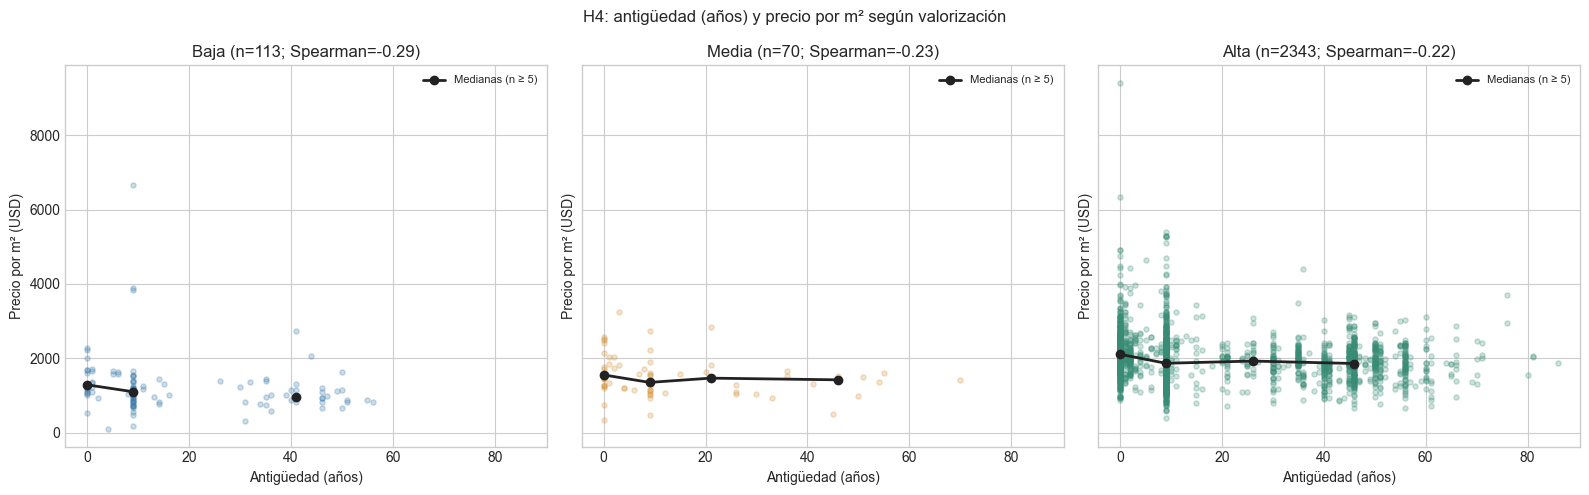

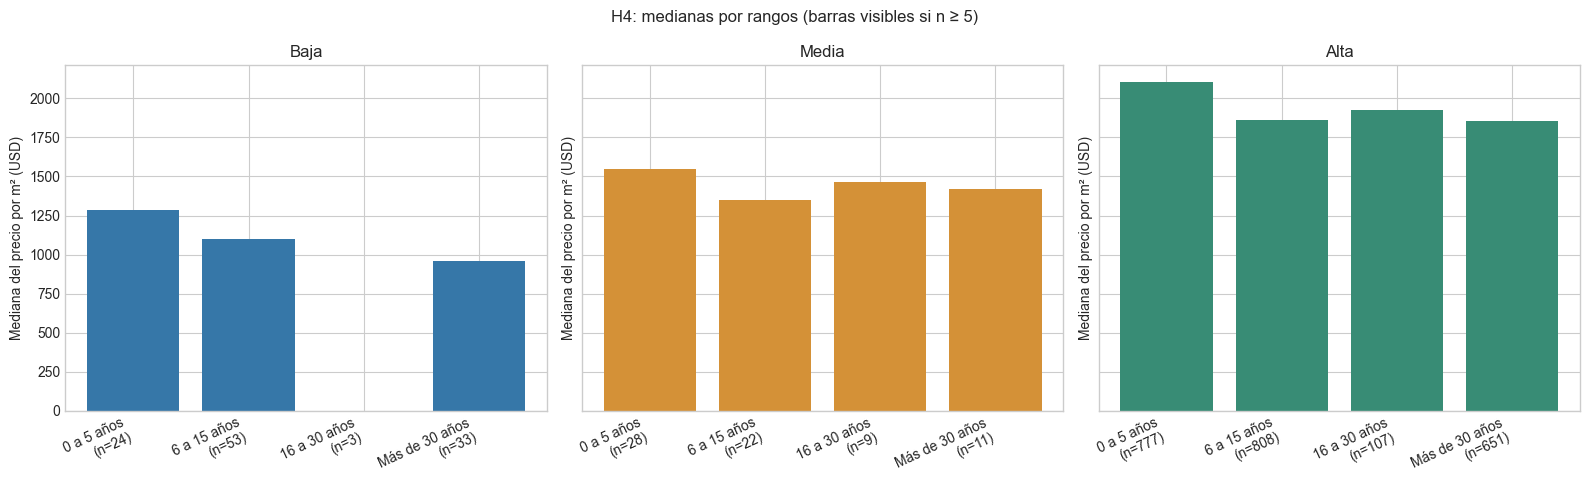

In [4]:
base_hipotesis['rango_antiguedad'] = pd.cut(
    base_hipotesis['antiguedad_calculada'], bins=[-1, 5, 15, 30, np.inf],
    labels=['0 a 5 años', '6 a 15 años', '16 a 30 años', 'Más de 30 años'])
resumen_h4, rangos_h4 = analizar_por_valorizacion(
    'antiguedad_calculada', 'rango_antiguedad', 'Antigüedad (años)', 'H4')


# 3. Evaluación de modelos de Machine Learning

Comparo regresión lineal, Random Forest y XGBoost con MAE, RMSE y R² para evaluar H1. Agrego una referencia que predice la mediana. El análisis corresponde al precio publicado de los departamentos de la muestra.

## 3.1 Importo las librerías

Importo las librerías y registro sus versiones para reproducir el análisis. Este apartado utiliza los datos preparados hasta 1.15.

In [11]:
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

SEMILLA_ML = 42
ANIO_REFERENCIA_ML = 2026
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', '{:,.3f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
    'numpy': np.__version__, 'scikit-learn': sklearn.__version__,
    'xgboost': xgboost.__version__}, name='versión').to_frame())

,versión
Python,3.13.14
pandas,2.2.3
numpy,2.2.5
scikit-learn,1.6.1
xgboost,2.1.4


## 3.2 Recupero los datos sin imputar y selecciono los predictores

Retomo los datos anteriores a 1.16 para imputar solo con información del entrenamiento. Excluyo las variables derivadas del precio, los identificadores y los textos. Conservo las superficies total y cubierta y uso la antigüedad referida a 2026 para reducir redundancias.

In [12]:
datos_ml = departamentos_limpios.dropna(
    subset=['barrio', 'latitud', 'longitud', 'distancia_al_mar_km']).copy().reset_index(drop=True)
comodidades_ml = [c for c in datos_ml if c.startswith('tiene_')]
datos_ml['cantidad_comodidades'] = datos_ml[comodidades_ml].eq('Sí').sum(axis=1)
datos_ml['antiguedad_calculada'] = (ANIO_REFERENCIA_ML - datos_ml['anio_construccion']).clip(lower=0)
datos_ml['cerca_del_centro'] = datos_ml['distancia_al_centro_km'].le(1).map(
    {True: 'Sí', False: 'No'}).where(datos_ml['distancia_al_centro_km'].notna())

numericas_ml = ['superficie_total_m2', 'superficie_cubierta_m2', 'ambientes',
    'dormitorios', 'banos', 'antiguedad_calculada', 'latitud', 'longitud',
    'distancia_al_mar_km', 'distancia_al_centro_km', 'cantidad_comodidades']
categoricas_ml = ['estado', 'disposicion', 'tipo_gas', 'barrio', 'tiene_balcon',
    'tiene_calefaccion', 'tiene_electricidad', 'tiene_gas_natural',
    'tiene_cocina_equipada', 'cerca_del_mar', 'cerca_del_centro']
X_ml = datos_ml[numericas_ml + categoricas_ml].copy()
X_ml[numericas_ml] = X_ml[numericas_ml].astype(float)
X_ml[categoricas_ml] = X_ml[categoricas_ml].astype(object).where(
    X_ml[categoricas_ml].notna(), np.nan)
y_ml = datos_ml['precio'].astype(float)
assert y_ml.notna().all() and y_ml.gt(0).all()
assert datos_ml['id_aviso'].is_unique
assert X_ml.isna().any().any(), 'La base debe conservar faltantes anteriores a la imputación.'
display(pd.DataFrame({'tipo': ['Numérica'] * len(numericas_ml) + ['Categórica'] * len(categoricas_ml),
    'faltantes': X_ml.isna().sum(), 'faltantes_pct': X_ml.isna().mean() * 100}))
print(f'Muestra: {len(X_ml):,} avisos y {X_ml.shape[1]} predictores.')

,tipo,faltantes,faltantes_pct
superficie_total_m2,Numérica,377,14.925
superficie_cubierta_m2,Numérica,1213,48.021
ambientes,Numérica,270,10.689
dormitorios,Numérica,395,15.637
banos,Numérica,18,0.713
antiguedad_calculada,Numérica,797,31.552
latitud,Numérica,0,0.000
longitud,Numérica,0,0.000
distancia_al_mar_km,Numérica,0,0.000
distancia_al_centro_km,Numérica,0,0.000


Muestra: 2,526 avisos y 22 predictores.


## 3.3 Separo entrenamiento y prueba

Separo el 80 % para entrenamiento y el 20 % para prueba, con semilla fija. Ajusto las configuraciones solo con entrenamiento.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X_ml, y_ml, test_size=0.20, random_state=SEMILLA_ML)
assert set(X_train.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_test) == len(X_ml)
display(pd.DataFrame({'conjunto': ['Entrenamiento', 'Prueba'],
    'avisos': [len(X_train), len(X_test)],
    'precio_mediano_USD': [y_train.median(), y_test.median()]}))
barrios_nuevos_ml = sorted(set(X_test['barrio']) - set(X_train['barrio']))
print(f'Barrios de prueba sin ejemplos en entrenamiento: {len(barrios_nuevos_ml)}')
if barrios_nuevos_ml:
    print(', '.join(barrios_nuevos_ml))

,conjunto,avisos,precio_mediano_USD
0,Entrenamiento,2020,"94,950.000"
1,Prueba,506,"89,950.000"


Barrios de prueba sin ejemplos en entrenamiento: 2
Roldán Belisario, Villa Lourdes


## 3.4 Preparo los datos y defino los modelos

Completo los faltantes, aplico One Hot Encoding y estandarizo los números para la regresión lineal. Uso los mismos predictores y ajusto las transformaciones dentro de cada entrenamiento para evitar fuga de información.

In [14]:
def crear_preprocesador_ml(escalar=False):
    pasos = [('imputar', SimpleImputer(strategy='median'))]
    if escalar:
        pasos.append(('escalar', StandardScaler()))
    return ColumnTransformer([
        ('numericas', Pipeline(pasos), numericas_ml),
        ('categoricas', Pipeline([
            ('imputar', SimpleImputer(strategy='constant', fill_value='No informado')),
            ('codificar', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
        ]), categoricas_ml)
    ], sparse_threshold=1.0)

estimadores_ml = {
    'Referencia (mediana)': DummyRegressor(strategy='median'),
    'Regresión lineal': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=250, random_state=SEMILLA_ML, n_jobs=2),
    'XGBoost': XGBRegressor(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        objective='reg:squarederror', tree_method='hist', random_state=SEMILLA_ML, n_jobs=2)
}
modelos_ml = {nombre: Pipeline([
    ('preparar', crear_preprocesador_ml(escalar=nombre == 'Regresión lineal')),
    ('modelo', estimador)
]) for nombre, estimador in estimadores_ml.items()}
grillas_ml = {
    'Random Forest': {'modelo__max_depth': [None, 12], 'modelo__min_samples_leaf': [1, 3]},
    'XGBoost': {'modelo__n_estimators': [200, 400], 'modelo__max_depth': [3, 5]}
}

## 3.5 Ajusto los modelos con validación cruzada

Comparo cuatro configuraciones por modelo de árboles con validación cruzada de cinco partes. Selecciono por menor MAE promedio y muestro el desvío para observar la variación entre particiones.

In [15]:
cv_ml = list(KFold(n_splits=5, shuffle=True, random_state=SEMILLA_ML).split(X_train))
metricas_ml = {'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
ajustados_ml, busquedas_ml, filas_cv_ml, configuraciones_ml = {}, {}, [], []
for nombre, modelo in modelos_ml.items():
    if nombre in grillas_ml:
        busqueda = GridSearchCV(modelo, grillas_ml[nombre], scoring=metricas_ml,
            refit='MAE', cv=cv_ml, n_jobs=1, error_score='raise')
        busqueda.fit(X_train, y_train)
        busquedas_ml[nombre] = busqueda
        ajustados_ml[nombre] = busqueda.best_estimator_
        pos = busqueda.best_index_
        resultado = {m: np.array([busqueda.cv_results_[f'split{k}_test_{m}'][pos]
                                 for k in range(5)]) for m in metricas_ml}
        configuraciones_ml.append({'modelo': nombre, 'configuración': str(busqueda.best_params_)})
    else:
        salida = cross_validate(modelo, X_train, y_train, cv=cv_ml,
            scoring=metricas_ml, n_jobs=1, error_score='raise')
        resultado = {m: salida[f'test_{m}'] for m in metricas_ml}
        ajustados_ml[nombre] = clone(modelo).fit(X_train, y_train)
    filas_cv_ml.append({'modelo': nombre,
        'MAE_CV_USD': -resultado['MAE'].mean(), 'MAE_desvio_USD': resultado['MAE'].std(ddof=1),
        'RMSE_CV_USD': -resultado['RMSE'].mean(), 'RMSE_desvio_USD': resultado['RMSE'].std(ddof=1),
        'R2_CV': resultado['R2'].mean(), 'R2_desvio': resultado['R2'].std(ddof=1)})
resultados_cv_ml = pd.DataFrame(filas_cv_ml).set_index('modelo').sort_values('MAE_CV_USD')
mejor_modelo_ml = resultados_cv_ml.index[0]
display(pd.DataFrame(configuraciones_ml).set_index('modelo'))
display(resultados_cv_ml)
print(f'Modelo seleccionado por MAE de validación: {mejor_modelo_ml}')

,configuración
modelo,
Random Forest,"{'modelo__max_depth': None, 'modelo__min_samples_leaf': 3}"
XGBoost,"{'modelo__max_depth': 5, 'modelo__n_estimators': 400}"


,MAE_CV_USD,MAE_desvio_USD,RMSE_CV_USD,RMSE_desvio_USD,R2_CV,R2_desvio
modelo,,,,,,
XGBoost,"19,362.591","1,595.671","36,329.731","5,249.577",0.736,0.040
Random Forest,"20,401.345","1,814.571","38,229.751","5,640.381",0.710,0.026
Regresión lineal,"25,615.164","1,581.338","43,200.715","5,107.070",0.620,0.102
Referencia (mediana),"44,054.781","4,776.404","73,697.931","12,614.959",-0.066,0.024


Modelo seleccionado por MAE de validación: XGBoost


## 3.6 Evalúo en prueba y reviso los errores

Evalúo los modelos sobre los mismos avisos de prueba y comparo el error con entrenamiento para revisar sobreajuste. Grafico los residuos y resumo los errores por tramo de precio para identificar dónde se equivocan más.

,MAE_train_USD,MAE_test_USD,RMSE_test_USD,R2_test,predicciones_negativas
modelo,,,,,
XGBoost,"7,807.533","17,894.230","32,123.976",0.754,0
Random Forest,"10,817.987","19,714.777","34,914.371",0.709,0
Regresión lineal,"23,491.225","25,665.552","42,102.798",0.577,3
Referencia (mediana),"44,031.167","42,594.484","66,251.275",-0.048,0


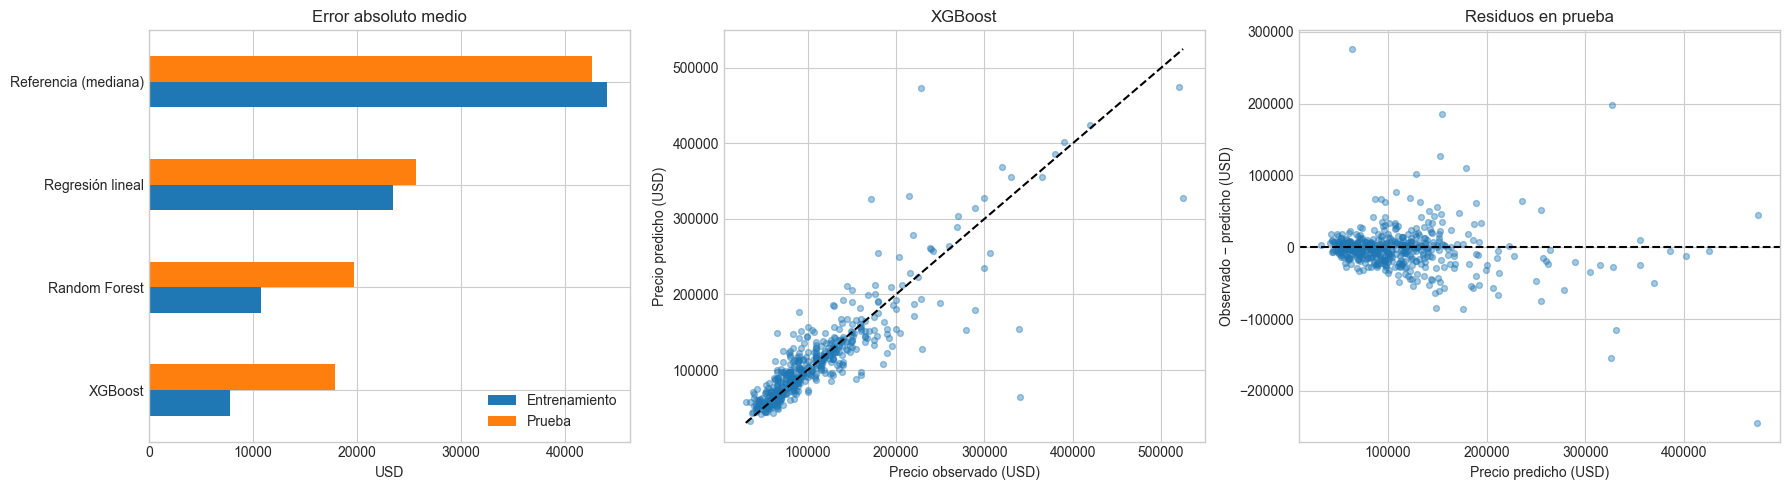

Cortes de precio del entrenamiento: USD 77,900 y USD 119,900.


,avisos,precio_mediano_USD,MAE_USD,residuo_medio_USD
tramo_precio,,,,
Bajo,181,"62,500.000","10,780.671","-6,842.654"
Medio,170,"91,950.000","13,885.571","-7,309.445"
Alto,155,"155,000.000","30,597.626","8,496.855"


Un residuo positivo indica subestimación. Estos tramos corresponden al precio de cada aviso, no al nivel de valorización del barrio.

In [ ]:
predicciones_ml, filas_prueba_ml = {}, []
for nombre, ajustado in ajustados_ml.items():
    pred_train = ajustado.predict(X_train)
    pred_test = ajustado.predict(X_test)
    assert np.isfinite(pred_test).all()
    predicciones_ml[nombre] = pred_test
    filas_prueba_ml.append({'modelo': nombre,
        'MAE_train_USD': mean_absolute_error(y_train, pred_train),
        'MAE_test_USD': mean_absolute_error(y_test, pred_test),
        'RMSE_test_USD': np.sqrt(mean_squared_error(y_test, pred_test)),
        'R2_test': r2_score(y_test, pred_test),
        'predicciones_negativas': int((pred_test < 0).sum())})
resultados_prueba_ml = pd.DataFrame(filas_prueba_ml).set_index('modelo').loc[resultados_cv_ml.index]
display(resultados_prueba_ml)

pred_mejor_ml = predicciones_ml[mejor_modelo_ml]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
resultados_prueba_ml[['MAE_train_USD', 'MAE_test_USD']].plot.barh(ax=axes[0])
axes[0].set(title='Error absoluto medio', xlabel='USD', ylabel='')
axes[0].legend(['Entrenamiento', 'Prueba'])
limites_ml = [min(y_test.min(), pred_mejor_ml.min()), max(y_test.max(), pred_mejor_ml.max())]
axes[1].scatter(y_test, pred_mejor_ml, alpha=.4, s=18)
axes[1].plot(limites_ml, limites_ml, '--', color='black')
axes[1].set(xlabel='Precio observado (USD)', ylabel='Precio predicho (USD)', title=mejor_modelo_ml)
axes[2].scatter(pred_mejor_ml, y_test.to_numpy() - pred_mejor_ml, alpha=.4, s=18)
axes[2].axhline(0, linestyle='--', color='black')
axes[2].set(xlabel='Precio predicho (USD)', ylabel='Observado − predicho (USD)', title='Residuos en prueba')
fig.tight_layout()
plt.show()

# Defino los tramos con el entrenamiento para revisar dónde se concentran los errores.
cortes_precio_ml = y_train.quantile([1/3, 2/3]).to_numpy()
errores_ml = pd.DataFrame({'precio_observado': y_test, 'precio_predicho': pred_mejor_ml})
errores_ml['residuo'] = errores_ml['precio_observado'] - errores_ml['precio_predicho']
errores_ml['error_absoluto'] = errores_ml['residuo'].abs()
errores_ml['tramo_precio'] = pd.cut(y_test, [-np.inf, *cortes_precio_ml, np.inf],
    labels=['Bajo', 'Medio', 'Alto'])
resumen_errores_ml = errores_ml.groupby('tramo_precio', observed=True).agg(
    avisos=('error_absoluto', 'size'), precio_mediano_USD=('precio_observado', 'median'),
    MAE_USD=('error_absoluto', 'mean'), residuo_medio_USD=('residuo', 'mean'))
print(f'Cortes de precio del entrenamiento: USD {cortes_precio_ml[0]:,.0f} y USD {cortes_precio_ml[1]:,.0f}.')
display(resumen_errores_ml)

## 3.7 Examino la importancia de las variables

Mezclo cada variable diez veces en prueba y mido cuánto aumenta el MAE para estimar su [importancia predictiva](https://scikit-learn.org/1.0/modules/permutation_importance.html).

,aumento_MAE_USD,desvio_USD
variable,,
superficie_total_m2,"16,484.090",765.581
banos,"2,130.224",475.988
ambientes,"2,023.909",174.489
superficie_cubierta_m2,"1,995.639",326.727
distancia_al_mar_km,"1,928.134",391.108
distancia_al_centro_km,"1,570.798",252.464
longitud,"1,528.158",266.898
tiene_balcon,"1,371.533",238.209
antiguedad_calculada,"1,363.400",148.264


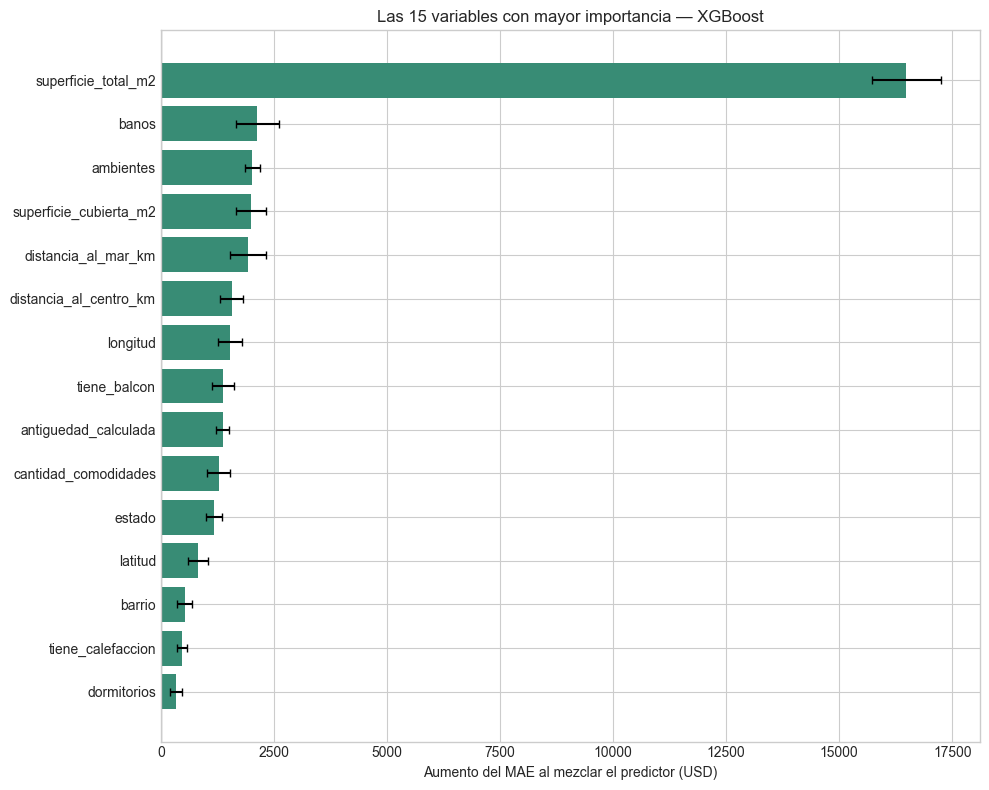

In [17]:
permutacion_ml = permutation_importance(ajustados_ml[mejor_modelo_ml], X_test, y_test,
    scoring='neg_mean_absolute_error', n_repeats=10, random_state=SEMILLA_ML, n_jobs=1)
importancias_ml = pd.DataFrame({'aumento_MAE_USD': permutacion_ml.importances_mean,
    'desvio_USD': permutacion_ml.importances_std}, index=X_ml.columns).sort_values('aumento_MAE_USD', ascending=False)
importancias_ml.index.name = 'variable'
display(importancias_ml)
grafico_importancias_ml = importancias_ml.head(15).sort_values('aumento_MAE_USD')
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(grafico_importancias_ml.index, grafico_importancias_ml['aumento_MAE_USD'],
    xerr=grafico_importancias_ml['desvio_USD'], color='#388c75', capsize=3)
ax.axvline(0, color='black', linewidth=.8)
ax.set(xlabel='Aumento del MAE al mezclar el predictor (USD)',
    title=f'Las 15 variables con mayor importancia — {mejor_modelo_ml}')
fig.tight_layout()
plt.show()

## 3.8 Evalúo H1 y presento las conclusiones



## 3.9 Comparo otros modelos con PyCaret

Comparo 15 modelos con sus configuraciones predeterminadas como complemento del análisis principal. Mantengo los mismos avisos de entrenamiento y prueba, cinco partes de validación y selección por MAE. PyCaret realiza su propia preparación de los datos en un [entorno separado](PYCARET.md).

In [14]:
import json
import os
import subprocess

raiz_pycaret = Path.cwd()
if not (raiz_pycaret / 'data').exists():
    raiz_pycaret = raiz_pycaret.parent
python_pycaret = raiz_pycaret / 'DATA_MODELING/.venv_pycaret' / (
    'Scripts/python.exe' if os.name == 'nt' else 'bin/python')
if not python_pycaret.exists():
    raise FileNotFoundError('Crear el entorno siguiendo DATA_MODELING/PYCARET.md.')
entrada_pycaret = raiz_pycaret / '.artifact_runtime/pycaret'
salida_pycaret = raiz_pycaret / 'DATA_MODELING/reportes/pycaret'
entrada_pycaret.mkdir(parents=True, exist_ok=True)

# Paso a PyCaret la misma separación, conservando los faltantes y los índices.
X_train.assign(precio=y_train).to_json(entrada_pycaret / 'entrenamiento.json',
    orient='split', double_precision=15)
X_test.assign(precio=y_test).to_json(entrada_pycaret / 'prueba.json',
    orient='split', double_precision=15)
(entrada_pycaret / 'config.json').write_text(json.dumps({
    'numericas': numericas_ml, 'categoricas': categoricas_ml, 'semilla': SEMILLA_ML
}, ensure_ascii=False), encoding='utf-8')

ejecucion_pycaret = subprocess.run([
    str(python_pycaret), str(raiz_pycaret / 'DATA_MODELING/pycaret_complementario.py'),
    '--entrada', str(entrada_pycaret), '--salida', str(salida_pycaret)
], cwd=raiz_pycaret, capture_output=True, text=True, encoding='utf-8', errors='replace')
if ejecucion_pycaret.returncode:
    raise RuntimeError(ejecucion_pycaret.stderr[-6000:])
info_pycaret = json.loads((salida_pycaret / 'ejecucion.json').read_text(encoding='utf-8'))
assert info_pycaret['entrenamiento'] == len(X_train)
assert info_pycaret['prueba'] == len(X_test)
print(f"PyCaret {info_pycaret['pycaret']}: {info_pycaret['modelos_comparados']} modelos, "
      f"{info_pycaret['entrenamiento']} avisos de entrenamiento y {info_pycaret['prueba']} de prueba.")


PyCaret 3.3.2: 15 modelos, 2020 avisos de entrenamiento y 506 de prueba.


,Modelo,MAE_CV_USD,RMSE_CV_USD,R2_CV
modelo_id,,,,
13,Extreme Gradient Boosting,"20,524.740","39,893.796",0.679
8,Random Forest Regressor,"20,577.672","40,478.587",0.675
11,Gradient Boosting Regressor,"20,963.656","36,904.798",0.726
9,Extra Trees Regressor,"21,151.390","39,579.154",0.681
5,Huber Regressor,"23,906.105","43,259.243",0.624
3,Elastic Net,"24,684.950","42,577.526",0.640
4,Bayesian Ridge,"25,206.386","42,662.060",0.630
1,Ridge Regression,"25,494.883","43,029.671",0.623
0,Linear Regression,"25,508.956","43,035.440",0.623


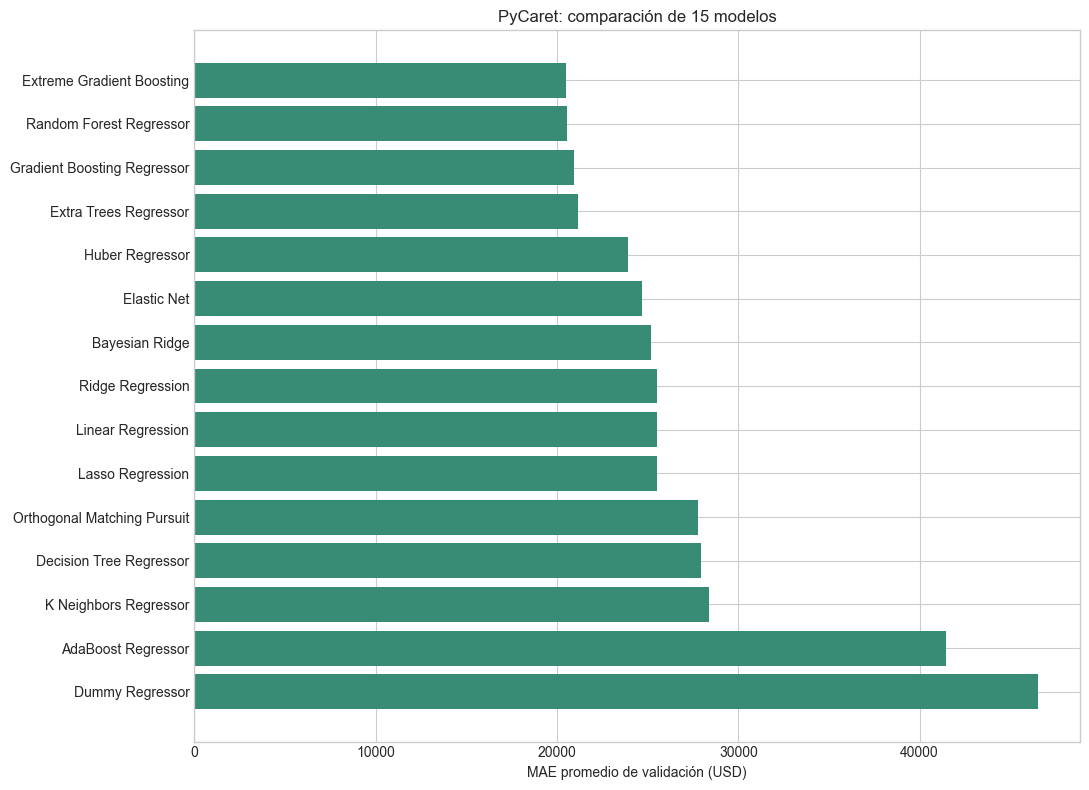

Evaluación en prueba del modelo seleccionado por validación:


,modelo,MAE_test_USD,RMSE_test_USD,R2_test
0,Extreme Gradient Boosting,"20,091.826","36,731.305",0.678


PyCaret seleccionó **Extreme Gradient Boosting** por su menor MAE de validación. En prueba obtuvo un MAE de **USD 20,092**, un RMSE de **USD 36,731** y un **R² de 0.678**.

In [15]:
comparacion_pycaret = pd.read_csv(salida_pycaret / 'comparacion_cv.csv', index_col='modelo_id')
prueba_pycaret = pd.read_csv(salida_pycaret / 'evaluacion_prueba.csv')
display(comparacion_pycaret[['Model', 'MAE', 'RMSE', 'R2']].rename(columns={
    'Model': 'Modelo', 'MAE': 'MAE_CV_USD', 'RMSE': 'RMSE_CV_USD', 'R2': 'R2_CV'}))

grafico_pycaret = comparacion_pycaret.head(15).sort_values('MAE', ascending=False)
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(grafico_pycaret['Model'], grafico_pycaret['MAE'], color='#388c75')
ax.set(title='PyCaret: comparación de 15 modelos', xlabel='MAE promedio de validación (USD)')
fig.tight_layout()
plt.show()

print('Evaluación en prueba del modelo seleccionado por validación:')
display(prueba_pycaret)
fila_pycaret = prueba_pycaret.iloc[0]
display(Markdown(f"PyCaret seleccionó **{fila_pycaret['modelo']}** por su menor MAE de validación. "
    f"En prueba obtuvo un MAE de **USD {fila_pycaret['MAE_test_USD']:,.0f}**, "
    f"un RMSE de **USD {fila_pycaret['RMSE_test_USD']:,.0f}** y un "
    f"**R² de {fila_pycaret['R2_test']:.3f}**."))
